# Paso 4B – Transformación final del dataset (Enfoque B) para clustering

**Proyecto:** perfiles de residentes del Puericultorio Pérez Araníbar (1INF03 – Análisis de datos).

Este cuaderno arma el **dataset final para el clustering** siguiendo tres insumos nuevos:

1. `Consideraciones/TA_Consolidado_Respuestas_FichaNominal (1).xlsx`: respuestas de la institución a las consultas sobre la ficha nominal. Las que están **Resueltas** o **Clarificadas** se aplican tal como las respondió la institución; las que siguen **En revisión** se tratan con la solución provisional más adecuada para el caso, con su justificación.
2. `Consideraciones/1INF03_TA_Puntos_de_Referencia (3).xlsx`: el equipo trabaja el **Enfoque B**, es decir, *todas las NNA presentes entre 2025-01 y 2026-07, con las variables de su último mes registrado más variables que resumen su historial*. El documento lista variables obligatorias, con alternativas de transformación separadas por `|`; aquí se elige una para cada variable y se justifica.
3. Las consideraciones para el clustering del mismo documento (Gower, hogar solo descriptivo, contraste de edad y sexo, PCA/MDS solo si se justifica).

**Punto de partida:** `Dataset_unificado_3.xlsx`, la salida del *Paso 3 – segunda parte*, que tiene un registro por NNA y mes, con la ficha nominal y la nutrición ya limpias, unidas y con el diagnóstico de mayor riesgo. **No se parte del Paso 4**, por tres razones:
- El Paso 4 tomó como población a los **122 residentes presentes en julio de 2026**, lo que corresponde al Enfoque A. El Enfoque B incluye también a quienes dejaron de figurar antes del corte.
- El Paso 4 calcula edad y permanencia a una fecha fija (31-07-2026). En el Enfoque B se calculan al **último mes registrado de cada NNA**, porque calcularlas a una fecha fija daría valores falsos para quienes ya no estaban.
- El Paso 4 ya había colapsado algunos textos (por ejemplo, la situación legal *"Desprotección Familiar"* quedó como `No estandarizado`), y la respuesta de la institución a INC-11 exige recuperar el texto original.

Los archivos de `ORIGINALES/` se usan solo para tres cosas que el consolidado 3 ya no tiene: (a) el texto original de la situación legal y de la UPE/juzgado, (b) los 12 códigos que el Paso 3 excluyó y que ahora se pueden recuperar, y (c) las evaluaciones nutricionales de esos 12 códigos. En cada caso se comprueba que la limpieza reproduce exactamente la del Paso 3.

# 1. Configuración y lectura del consolidado 3

In [1]:
from pathlib import Path
import re
import unicodedata
import datetime as dt
import warnings
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 220)

BASE = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
RUTA_U3 = BASE / 'Dataset_unificado_3.xlsx'                       # salida del Paso 3 (segunda parte)
RUTA_FICHA = BASE / 'ORIGINALES' / 'FichaNominal_consolidado_IDs_v2.xlsx'
RUTA_NUT = BASE / 'ORIGINALES'                                     # 6 libros de nutrición
RUTA_SALIDA = BASE / 'Resultados_EnfoqueB'
RUTA_EVID = RUTA_SALIDA / 'Evidencias_Paso4B'
RUTA_EVID.mkdir(parents=True, exist_ok=True)

PERIODO_INI, PERIODO_FIN = '2025-01', '2026-07'   # ventana del Enfoque B
PERIODO_NUT_MAX = '2026-08'                       # última evaluación nutricional disponible (ver INC-16)

u3 = pd.read_excel(RUTA_U3)
NOM = [c for c in u3.columns if c.startswith('nom_')]
con_ficha = u3[NOM].notna().any(axis=1)
print(f'Consolidado 3: {u3.shape[0]:,} registros x {u3.shape[1]} columnas | NNA: {u3["id_persona"].nunique()}')
print(f'Registros con ficha nominal: {con_ficha.sum():,} | solo nutrición: {(~con_ficha).sum()}')
print('Periodos:', u3['periodo'].min(), 'a', u3['periodo'].max())

Consolidado 3: 2,459 registros x 43 columnas | NNA: 145
Registros con ficha nominal: 2,422 | solo nutrición: 37
Periodos: 2025-01 a 2026-08


**Comentario 1:** el consolidado 3 tiene 2 459 registros de 145 NNA: 2 422 con ficha nominal y 37 solo con evaluación nutricional (agosto de 2026 y algunos meses de enero y febrero sin ficha). Le faltan 12 de los 157 códigos de la ficha original, porque el Paso 3 excluyó 8 por identidad inconsistente y 4 por cronología incompatible. Los dos casos siguen **En revisión** en el consolidado de respuestas (INC-01 e INC-06), así que se reevalúan en la sección 3.

# 2. Funciones de limpieza y lectura de la ficha original

Se aplican las mismas reglas del Paso 3 para que los datos recuperados de los originales sean comparables con el consolidado 3:
- Se quitan las comillas y los espacios o saltos de línea sobrantes.
- Fechas: `AAAA-MM-DD` cuando el separador es `-` y **`DD/MM/AAAA` cuando el separador es `/`**. Esta regla la **confirmó la institución en INC-17** («Se registra siempre DD/MM/AAAA»).
- `NA` y `No tiene` en las columnas de fecha quedan vacíos.

In [2]:
def txt(v):
    """Texto limpio: sin comillas, sin espacios sobrantes; vacío -> NaN."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return np.nan
    t = re.sub(r'\s+', ' ', str(v)).strip().strip('"').strip()
    return t if t not in ('', 'NA', 'nan') else np.nan


def norm(x):
    """Minúsculas, sin tildes y con espacios simples (solo para comparar textos)."""
    if pd.isna(x):
        return np.nan
    t = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'\s+', ' ', t).strip()


def fecha(v):
    """INC-17: con '/' siempre es DD/MM/AAAA; con '-' es AAAA-MM-DD."""
    if isinstance(v, (dt.date, dt.datetime)):
        return pd.Timestamp(v)
    t = txt(v)
    if pd.isna(t):
        return pd.NaT
    for f in ('%Y-%m-%d', '%d/%m/%Y', '%d/%m/%y'):
        try:
            return pd.Timestamp(dt.datetime.strptime(t, f))
        except ValueError:
            pass
    return pd.NaT


wb = openpyxl.load_workbook(RUTA_FICHA, read_only=True)
filas = list(wb.worksheets[0].iter_rows(values_only=True))
wb.close()
orig = pd.DataFrame(filas[1:], columns=filas[0])
orig.insert(0, 'fila_excel', orig.index + 2)
orig['periodo'] = orig['periodo'].map(txt).str.replace('_', '-')
orig['IDs_FichaNominal'] = orig['IDs_FichaNominal'].map(txt)
print(f'Ficha original: {orig.shape[0]:,} filas | {orig["IDs_FichaNominal"].nunique()} códigos | {orig["periodo"].nunique()} meses')

# Control: la limpieza reproduce el consolidado 3 en los 133 códigos que el Paso 3 conservó
FECHAS = ['nom_Fecha de ingreso', 'nom_Fecha de la Resolucion Administrativa', 'nom_Fecha del Oficio de Ingreso',
          'nom_FECHA ELABORACIÓN Plan de Trabajo individual - PTI']
a = orig[orig['IDs_FichaNominal'].isin(u3['id_persona'])].set_index(['IDs_FichaNominal', 'periodo'])
b = u3[con_ficha].set_index(['id_persona', 'periodo'])
control = []
for c in ['fecha_nacimiento'] + NOM:
    col_o = 'Fecha de nacimiento' if c == 'fecha_nacimiento' else c[4:]
    if c in ['fecha_nacimiento'] + FECHAS:
        va, vb = a[col_o].map(fecha), b[c]
    else:
        va, vb = a[col_o].map(txt).map(norm), b[c].map(norm)
    j = pd.concat([va.rename('o'), vb.rename('u')], axis=1, join='inner')
    distintos = int(((j['o'] != j['u']) & ~(j['o'].isna() & j['u'].isna())).sum())
    control.append({'columna': c, 'registros_comparados': len(j), 'distintos': distintos})
control = pd.DataFrame(control)
homologadas = ['nom_Situación Legal de la (NNA)', 'nom_Nombre de UPE /Juzgado', 'nom_Tipo de Institución Educativa', 'nom_Nacionalidad']
print('Columnas con diferencias (deben ser solo las que el Paso 3 homologó a propósito):')
control[control['distintos'] > 0]

Ficha original: 2,667 filas | 157 códigos | 19 meses


Columnas con diferencias (deben ser solo las que el Paso 3 homologó a propósito):


,columna,registros_comparados,distintos
4,nom_Nacionalidad,2422,1459
9,nom_Situación Legal de la (NNA),2422,2422
11,nom_Nombre de UPE /Juzgado,2422,2422
18,nom_Tipo de Institución Educativa,2422,2422


**Comentario 2:** la ficha original tiene 2 667 filas, 157 códigos y 19 meses (enero 2025 a julio 2026). Para los 133 códigos que conservó el Paso 3 se compararon, celda por celda, las fechas y los textos limpiados aquí contra el consolidado 3: **coinciden en las 2 422 fichas**. Las únicas diferencias están en las cuatro columnas que el Paso 3 homologó a propósito (situación legal, UPE, tipo de institución y nacionalidad). Esto confirma que las filas que se recuperan de los originales se limpian con el mismo criterio que el resto del consolidado.

# 3. Consultas **En revisión**: tratamiento elegido

## 3.1 INC-01 – Códigos que agrupan datos contradictorios (8 códigos)

La institución todavía no respondió. La solución provisional consensuada entre equipos es la **clave compuesta (ID + sexo + fecha de nacimiento)** con sufijos provisionales. Antes de aplicarla se revisa qué cambia en cada código.

In [3]:
IDS_INC01 = ['PPA_FN_0010', 'PPA_FN_0020', 'PPA_FN_0025', 'PPA_FN_0035', 'PPA_FN_0036', 'PPA_FN_0071', 'PPA_FN_0082', 'PPA_FN_0127']
IDS_INC06 = ['PPA_FN_0004', 'PPA_FN_0033', 'PPA_FN_0034', 'PPA_FN_0073']

rec = orig[orig['IDs_FichaNominal'].isin(IDS_INC01 + IDS_INC06)].copy()
r = pd.DataFrame({'id_original': rec['IDs_FichaNominal'], 'periodo': rec['periodo'], 'fila_excel': rec['fila_excel'],
                  'sexo': rec['Sexo'].map(txt), 'fecha_nacimiento': rec['Fecha de nacimiento'].map(fecha)})
for c in NOM:
    r[c] = rec[c[4:]].map(fecha) if c in FECHAS else rec[c[4:]].map(txt)
r['sit_legal_texto'] = rec['Situación Legal de la (NNA)'].map(txt)
r['upe_texto'] = rec['Nombre de UPE /Juzgado'].map(txt)
r['id_persona'] = r['id_original']

claves_inc01 = (r[r['id_original'].isin(IDS_INC01)]
                .groupby(['id_original', 'sexo', 'fecha_nacimiento', 'nom_Fecha de ingreso', 'nom_Fecha del Oficio de Ingreso'])
                ['periodo'].agg(desde='min', hasta='max', fichas='size').reset_index())
claves_inc01

,id_original,sexo,fecha_nacimiento,nom_Fecha de ingreso,nom_Fecha del Oficio de Ingreso,desde,hasta,fichas
0,PPA_FN_0010,M,2019-11-11,2020-01-22,2020-01-22,2025-01,2025-09,9
1,PPA_FN_0010,M,2019-12-10,2020-01-22,2020-01-22,2025-10,2026-07,10
2,PPA_FN_0020,F,2017-12-14,2018-01-08,2018-01-08,2025-01,2026-07,19
3,PPA_FN_0020,F,2024-12-28,2024-12-30,2025-01-02,2025-01,2025-01,1
4,PPA_FN_0020,M,2017-04-24,2021-05-19,2021-05-19,2025-01,2025-09,8
5,PPA_FN_0020,M,2025-01-12,2025-06-17,2025-06-17,2025-02,2025-09,5
6,PPA_FN_0020,M,2025-06-01,2025-07-15,2025-07-15,2025-02,2025-08,3
7,PPA_FN_0025,F,2018-12-31,2020-01-22,2020-01-22,2025-10,2026-07,10
8,PPA_FN_0025,F,2019-01-22,2020-01-22,2020-01-22,2025-01,2025-09,9
9,PPA_FN_0035,F,2014-11-06,2019-10-21,2019-10-21,2026-03,2026-07,5


Para contrastar se extraen las evaluaciones nutricionales de los 6 libros originales, que traen **su propia fecha de nacimiento** y sirven como fuente independiente. El extractor sigue las reglas del Paso 3: encabezado en la fila 3, primer bloque de diagnósticos = curva OMS y segundo = tabla INS, las mismas correcciones de texto y el diagnóstico de mayor riesgo. Se valida contra las 343 evaluaciones que ya están en el consolidado 3.

In [4]:
CORR_DX = {'NORNAL': 'NORMAL', 'OBEESIDAD': 'OBESIDAD', 'OBESIDA': 'OBESIDAD', 'RIESO TALLA BAJA': 'RIESGO TALLA BAJA',
           'RIESGO TALA BAJA': 'RIESGO TALLA BAJA', 'RIESGO DE TALLA BAJA': 'RIESGO TALLA BAJA', 'RIESGO DE SOBREPESO': 'RIESGO SOBREPESO',
           'RIESGO SOBRE PESO': 'RIESGO SOBREPESO', 'SOBRE PESO': 'SOBREPESO', 'ALTA': 'ALTO', 'DESNUTRIDO': 'BAJO PESO',
           'RIEGO DE DELGADEZ O RIESGO DE BAJO PESO': 'RIESGO BAJO PESO', 'RIESGO DE DELGADEZ O RIESGO DE BAJO PESO': 'RIESGO BAJO PESO'}
NIVEL_RIESGO = {'NORMAL': 0, 'ALTO': 0.5, 'RIESGO BAJO PESO': 1, 'RIESGO SOBREPESO': 1, 'RIESGO TALLA BAJA': 1, 'BAJO PESO': 2,
                'SOBREPESO': 2, 'TALLA BAJA': 2, 'RIESGO OBESIDAD': 2, 'BAJO PESO SEVERO': 3, 'TALLA BAJA SEVERA': 3, 'OBESIDAD': 3, 'OBESIDAD III': 4}


def dx(v):
    t = txt(v)
    t = '' if pd.isna(t) else t.upper()
    return np.nan if t in ('', '*') else CORR_DX.get(t, t)


def extraer_nutricion(carpeta):
    out = []
    for path in sorted(Path(carpeta).glob('Nutricion*.xlsx')):
        per = re.search(r'2026(\d{2})', path.name).group(0)
        per = per[:4] + '-' + per[4:]
        libro = openpyxl.load_workbook(path, data_only=True)
        for hoja in libro:
            filas = list(hoja.iter_rows(values_only=True))
            if len(filas) < 3:
                continue
            enc = [('' if pd.isna(txt(h)) else txt(h).upper()) for h in filas[2]]
            i_peso = next(i for i, h in enumerate(enc) if 'PESO' in h)
            i_talla = next(i for i, h in enumerate(enc) if 'TALLA' in h)
            ini_dx = min(i for i, h in enumerate(enc) if h in ('P/E', 'T/E'))   # el IMC anterior es el numérico
            ind = {'P/E': 'pe', 'T/E': 'te', 'P/T': 'pt', 'IMC': 'imc', 'IMC/E': 'imc'}
            cols, vistos = {}, {}
            for i, h in enumerate(enc):
                if h in ind and i >= ini_dx:
                    k = ind[h]
                    vistos[k] = vistos.get(k, 0) + 1
                    cols[(k, 'curva' if vistos[k] == 1 else 'tabla')] = i
            hogar = 'INFANTES' if ('INFANTES' in hoja.title.upper() or hoja.title.startswith('Eva.Nut')) else hoja.title.strip()
            casa = None
            for nf, fila in enumerate(filas, 1):
                g = lambda i: fila[i] if i is not None and i < len(fila) else None
                if nf > 3 and isinstance(g(0), str) and txt(g(0)).upper().startswith('CASA'):
                    casa = txt(g(0))
                    continue
                if not re.fullmatch(r'PPA_FN_\d+', str(g(1))):
                    continue
                w, h = g(i_peso), g(i_talla)
                e = dict(id_persona=g(1), periodo=per, hogar=hogar, casa=casa, fnac_nutricion=fecha(g(2)),
                         peso=w if isinstance(w, (int, float)) else np.nan, talla=h if isinstance(h, (int, float)) else np.nan,
                         provincia=str(txt(w)).upper() == 'PROVINCIA', archivo=path.name, hoja=hoja.title, fila=nf)
                for k in ['pe', 'te', 'pt', 'imc']:
                    c = dx(g(cols.get((k, 'curva'))))
                    t = dx(g(cols.get((k, 'tabla'))))
                    usar_tabla = pd.notna(t) and (pd.isna(c) or NIVEL_RIESGO.get(t, -1) > NIVEL_RIESGO.get(c, -1))
                    e[f'dx_{k}'] = t if usar_tabla else c        # mayor riesgo entre curva y tabla (Paso 3)
                out.append(e)
    df = pd.DataFrame(out)
    df['imc'] = df['peso'] / (df['talla'] / 100) ** 2
    return df


nut_orig = extraer_nutricion(RUTA_NUT)
print(f'Evaluaciones extraídas: {len(nut_orig)} | con PROVINCIA (sin medición): {nut_orig["provincia"].sum()}')

# Validación contra el consolidado 3
ev3 = u3[u3['nut_id_evaluacion'].notna()]
v = ev3.merge(nut_orig[~nut_orig['provincia']], on=['id_persona', 'periodo'], suffixes=('_u3', '_orig'))
val = {'evaluaciones comparadas': len(v),
       'peso distinto': int((v['nut_peso_kg'] - v['peso']).abs().gt(0.001).sum()),
       'talla distinta': int((v['nut_talla_cm'] - v['talla']).abs().gt(0.001).sum()),
       'IMC con diferencia > 0.15': int((v['nut_imc_completado'] - v['imc']).abs().gt(0.15).sum())}
for k in ['pe', 'te', 'pt', 'imc']:
    val[f'dx_{k} distinto'] = int((v[f'dx_{k}_u3'].fillna('-') != v[f'dx_{k}_orig'].fillna('-')).sum())
pd.Series(val).to_frame('resultado')

Evaluaciones extraídas: 402 | con PROVINCIA (sin medición): 23


,resultado
evaluaciones comparadas,343
peso distinto,0
talla distinta,0
IMC con diferencia > 0.15,0
dx_pe distinto,0
dx_te distinto,0
dx_pt distinto,0
dx_imc distinto,0


**Comentario 3:** el extractor reproduce **exactamente** las 343 evaluaciones del consolidado 3: el mismo peso, la misma talla y los mismos cuatro diagnósticos. Se puede usar con confianza para los códigos recuperados.

Ahora se cruza la fecha de nacimiento que trae nutrición con la de la ficha para los 12 códigos excluidos:

In [5]:
nut12 = nut_orig[nut_orig['id_persona'].isin(IDS_INC01 + IDS_INC06)]
fn_ficha = r.groupby(['id_original', 'fecha_nacimiento'])['periodo'].agg(['min', 'max']).reset_index()
fn_nut = nut12.groupby('id_persona')['fnac_nutricion'].agg(lambda s: sorted(set(s.dropna()))).rename('fecha_nac_en_nutricion')
cruce = fn_ficha.merge(fn_nut, left_on='id_original', right_index=True, how='left')
cruce['coincide_con_nutricion'] = [f in (l if isinstance(l, list) else []) for f, l in zip(cruce['fecha_nacimiento'], cruce['fecha_nac_en_nutricion'])]
cruce.rename(columns={'min': 'ficha_desde', 'max': 'ficha_hasta'})

,id_original,fecha_nacimiento,ficha_desde,ficha_hasta,fecha_nac_en_nutricion,coincide_con_nutricion
0,PPA_FN_0004,2023-09-01,2025-01,2026-07,[2023-01-09 00:00:00],False
1,PPA_FN_0010,2019-11-11,2025-01,2025-09,[2019-12-10 00:00:00],False
2,PPA_FN_0010,2019-12-10,2025-10,2026-07,[2019-12-10 00:00:00],True
3,PPA_FN_0020,2017-04-24,2025-01,2025-09,[2017-12-14 00:00:00],False
4,PPA_FN_0020,2017-12-14,2025-01,2026-07,[2017-12-14 00:00:00],True
5,PPA_FN_0020,2024-12-28,2025-01,2025-01,[2017-12-14 00:00:00],False
6,PPA_FN_0020,2025-01-12,2025-02,2025-09,[2017-12-14 00:00:00],False
7,PPA_FN_0020,2025-06-01,2025-02,2025-08,[2017-12-14 00:00:00],False
8,PPA_FN_0025,2018-12-31,2025-10,2026-07,[2018-12-31 00:00:00],True
9,PPA_FN_0025,2019-01-22,2025-01,2025-09,[2018-12-31 00:00:00],False


**Comentario 4 – decisión para INC-01.** Los 8 códigos no tienen el mismo problema:

| Caso | Códigos | Evidencia | Tratamiento |
|---|---|---|---|
| **Dato corregido a mitad del periodo** (una sola persona) | 0010, 0025, 0127 | La fecha de nacimiento cambia en oct-2025 y **la nueva coincide con la de nutrición**. En 0127 la fecha anterior era la misma fecha de ingreso, es decir, un error de copia. | Una persona. Los datos fijos toman el valor **más reciente** |
| Fecha de ingreso u oficio corregida | 0035, 0036, 0071, 0082 | Cambia la fecha de ingreso (en 0071 es una inversión día/mes, 2015-04-12 → 2015-12-04). El valor más reciente coincide con la **fecha del oficio de ingreso** | Una persona. Valor más reciente |
| **Código que agrupa a 5 NNA distintos** | 0020 | 5 combinaciones de sexo y nacimiento, con fichas solapadas en el mismo mes | Desagregación por clave compuesta en `PPA_FN_0020_A` a `_E` (solución consensuada) |

- 0035 y 0036, y también 0033 y 0034, tienen los mismos datos personales, pero sus pesos y tallas son distintos en nutrición. Son personas distintas (probablemente hermanas gemelas), así que se mantienen separadas.
- En 0020, la NNA con 19 meses de ficha (F, 2017-12-14) es la única que coincide con nutrición, por eso recibe el sufijo `_A`. Los otros cuatro reciben `_B` a `_E` por orden de nacimiento.
- **Por qué recuperar y no excluir:** el Enfoque B busca a *todas* las NNA presentes en el periodo, y excluir 12 códigos (7 % de la población) sesgaría el análisis contra los casos con registros más desordenados. Todos quedan marcados en la columna `id_recuperado`, para medir en el clustering si su inclusión cambia los resultados.

In [6]:
# 0020: desagregación por clave compuesta (sexo + fecha de nacimiento)
m20 = r['id_original'] == 'PPA_FN_0020'
claves20 = r[m20].groupby(['sexo', 'fecha_nacimiento']).size().reset_index().sort_values('fecha_nacimiento')
sufijo = {('F', pd.Timestamp('2017-12-14')): 'A'}            # la que coincide con nutrición y tiene 19 meses
letras = iter('BCDE')
for _, k in claves20.iterrows():
    if (k['sexo'], k['fecha_nacimiento']) not in sufijo:
        sufijo[(k['sexo'], k['fecha_nacimiento'])] = next(letras)
r.loc[m20, 'id_persona'] = [f'PPA_FN_0020_{sufijo[(s, f)]}' for s, f in zip(r.loc[m20, 'sexo'], r.loc[m20, 'fecha_nacimiento'])]

# Códigos con un dato fijo corregido en el tiempo: se usa el valor más reciente (validado con nutrición u oficio)
FIJOS = ['fecha_nacimiento', 'nom_Fecha de ingreso', 'nom_Fecha del Oficio de Ingreso', 'nom_Nacionalidad']
for pid in ['PPA_FN_0010', 'PPA_FN_0025', 'PPA_FN_0127', 'PPA_FN_0035', 'PPA_FN_0036', 'PPA_FN_0071', 'PPA_FN_0082']:
    m = r['id_persona'] == pid
    ult = r[m].sort_values('periodo').iloc[-1]
    for c in FIJOS:
        r.loc[m, c] = ult[c]

assert not r.duplicated(['id_persona', 'periodo']).any()
r[m20].groupby('id_persona').agg(sexo=('sexo', 'first'), nacimiento=('fecha_nacimiento', 'first'),
                                 ingreso=('nom_Fecha de ingreso', 'first'), desde=('periodo', 'min'), hasta=('periodo', 'max'), fichas=('periodo', 'size'))

,sexo,nacimiento,ingreso,desde,hasta,fichas
id_persona,,,,,,
PPA_FN_0020_A,F,2017-12-14,2018-01-08,2025-01,2026-07,19
PPA_FN_0020_B,M,2017-04-24,2021-05-19,2025-01,2025-09,8
PPA_FN_0020_C,F,2024-12-28,2024-12-30,2025-01,2025-01,1
PPA_FN_0020_D,M,2025-01-12,2025-06-17,2025-02,2025-09,5
PPA_FN_0020_E,M,2025-06-01,2025-07-15,2025-02,2025-08,3


## 3.2 INC-06 – Cronologías imposibles (4 códigos) y fichas anteriores al ingreso

Tampoco hay respuesta de la institución. La solución provisional consensuada es *detectar inversiones día/mes y, si no se resuelven, usar la fecha del oficio o de la resolución*. Se revisa caso por caso:

In [7]:
r[r['id_original'].isin(IDS_INC06)][['id_original', 'fecha_nacimiento', 'nom_Fecha de ingreso', 'nom_Fecha de la Resolucion Administrativa',
                                      'nom_Fecha del Oficio de Ingreso']].drop_duplicates().merge(fn_nut, left_on='id_original', right_index=True)

,id_original,fecha_nacimiento,nom_Fecha de ingreso,nom_Fecha de la Resolucion Administrativa,nom_Fecha del Oficio de Ingreso,fecha_nac_en_nutricion
3,PPA_FN_0004,2023-09-01,2023-01-16,2023-01-16,2023-01-16,[2023-01-09 00:00:00]
33,PPA_FN_0033,2014-04-12,2014-03-06,2014-06-03,2014-06-03,[2014-04-12 00:00:00]
34,PPA_FN_0034,2014-04-12,2014-03-06,2014-06-03,2014-06-03,[2014-04-12 00:00:00]
73,PPA_FN_0073,2014-05-17,2014-01-08,2014-01-08,2014-01-08,[2014-05-17 00:00:00]


**Comentario 5 – decisión para INC-06.** En los cuatro casos hay una corrección única y verificable:

| Código | Problema | Evidencia | Corrección |
|---|---|---|---|
| 0033, 0034 | Ingreso `2014-03-06`, nacimiento 12-04-2014 | Resolución y oficio: **2014-06-03**. Es la misma fecha con el día y el mes invertidos | Ingreso = 2014-06-03 |
| 0073 | Ingreso, resolución y oficio `2014-01-08`, nacimiento 17-05-2014 | Nutrición confirma el nacimiento; la única lectura posible es la inversión (**2014-08-01**) | Ingreso, resolución y oficio = 2014-08-01 |
| 0004 | Nacimiento `2023-09-01`, ingreso 16-01-2023 | **Nutrición registra 2023-01-09** (inversión día/mes), y está en *Inicial 3 años* en 2026, lo que solo cuadra con haber nacido en enero de 2023 | Nacimiento = 2023-01-09 |

**Fichas anteriores al ingreso** (segunda parte de INC-06): 11 NNA (PPA_FN_0145 a 0155) aparecen en la ficha de febrero de 2025 con un ingreso formal posterior (marzo a julio). Lo mismo pasa con dos de las NNA desagregadas de 0020. Mientras la institución no aclare si ingresaron físicamente antes, se aplica la solución consensuada: **se excluyen las filas del panel anteriores al mes de ingreso** y se conserva a la NNA. Esas filas inflarían el historial (meses sin PTI, meses observados) con meses en que la NNA formalmente no estaba en el CAR.

In [8]:
r.loc[r['id_persona'].isin(['PPA_FN_0033', 'PPA_FN_0034']), 'nom_Fecha de ingreso'] = pd.Timestamp('2014-06-03')
r.loc[r['id_persona'] == 'PPA_FN_0073', ['nom_Fecha de ingreso', 'nom_Fecha de la Resolucion Administrativa',
                                         'nom_Fecha del Oficio de Ingreso']] = pd.Timestamp('2014-08-01')
r.loc[r['id_persona'] == 'PPA_FN_0004', 'fecha_nacimiento'] = pd.Timestamp('2023-01-09')
r['id_recuperado'] = np.where(r['id_original'] == 'PPA_FN_0020', 'INC-01 desagregado',
                      np.where(r['id_original'].isin(IDS_INC01), 'INC-01 dato corregido', 'INC-06 cronología corregida'))

# Panel mensual: consolidado 3 (133 códigos) + 12 códigos recuperados (16 NNA)
raw = orig[['IDs_FichaNominal', 'periodo', 'Situación Legal de la (NNA)', 'Nombre de UPE /Juzgado']].copy()
raw.columns = ['id_persona', 'periodo', 'sit_legal_texto', 'upe_texto']
raw = raw[~raw['id_persona'].isin(IDS_INC01 + IDS_INC06)]
raw['sit_legal_texto'] = raw['sit_legal_texto'].map(txt)
raw['upe_texto'] = raw['upe_texto'].map(txt)
assert not raw.duplicated(['id_persona', 'periodo']).any()

fu = u3[con_ficha].copy()
fu['id_original'] = fu['id_persona']
fu['id_recuperado'] = 'No'
fu = fu.merge(raw, on=['id_persona', 'periodo'], how='left', validate='one_to_one')
COLS_PANEL = ['id_persona', 'id_original', 'id_recuperado', 'periodo', 'sexo', 'fecha_nacimiento'] + NOM + ['sit_legal_texto', 'upe_texto']
fichas = pd.concat([fu[COLS_PANEL], r[COLS_PANEL]], ignore_index=True)
fichas = fichas[(fichas['periodo'] >= PERIODO_INI) & (fichas['periodo'] <= PERIODO_FIN)]

antes_ingreso = pd.PeriodIndex(fichas['periodo'], freq='M') < fichas['nom_Fecha de ingreso'].dt.to_period('M')
excl_antes = fichas[antes_ingreso].copy()
fichas = fichas[~antes_ingreso].sort_values(['id_persona', 'periodo']).reset_index(drop=True)
fichas['fin_mes'] = pd.PeriodIndex(fichas['periodo'], freq='M').to_timestamp(how='end').normalize()

assert not (fichas['nom_Fecha de ingreso'] < fichas['fecha_nacimiento']).any(), 'quedan cronologías imposibles'
assert not fichas.duplicated(['id_persona', 'periodo']).any()
print(f'Fichas anteriores al ingreso excluidas: {len(excl_antes)} ({excl_antes["id_persona"].nunique()} NNA, periodos {sorted(excl_antes["periodo"].unique())})')
print(f'Panel Enfoque B: {len(fichas):,} fichas | {fichas["id_persona"].nunique()} NNA')
fichas.groupby('id_recuperado')['id_persona'].nunique().rename('NNA').to_frame()

Fichas anteriores al ingreso excluidas: 13 (13 NNA, periodos ['2025-02'])
Panel Enfoque B: 2,654 fichas | 161 NNA


,NNA
id_recuperado,
INC-01 dato corregido,7
INC-01 desagregado,5
INC-06 cronología corregida,4
No,145


**Comentario 6:** con las correcciones ya no queda ninguna cronología imposible ni ninguna NNA con dos fichas en el mismo mes. Se excluyen 13 fichas anteriores al ingreso (de 13 NNA, todas de febrero de 2025) y el panel queda con **161 NNA**: 145 del consolidado 3, 11 recuperados como una sola persona y 5 que salen de desagregar 0020.

> El documento de referencia indica 156 NNA presentes entre 202501 y 202607. La diferencia se explica porque aquí 0020 se desagrega en 5 personas (157 códigos − 1 + 5 = 161). El número exacto depende de la respuesta pendiente de la institución a INC-01.

## 3.3 INC-16 – NNA evaluados por nutrición después de su última ficha y egresos sin motivo

No hay respuesta. Se aplican tres criterios:
- **Egresos:** las 27 NNA cuya última ficha es anterior a julio de 2026 se consideran **egresos presuntos** del periodo. El Enfoque B los incluye a propósito, con las variables de su último mes registrado. Se marcan en `activo_al_corte` (0/1) solo para describir los clusters, no para modelar, porque la base no tiene motivos ni fechas de egreso.
- **Nutrición posterior a la última ficha** (0090, 0144, 0154 y 0155 en ene/feb 2026): estas evaluaciones prueban que la NNA seguía en el CAR, así que se usan para las variables nutricionales.
- **Evaluaciones de agosto de 2026** (32, solo adolescentes de Matogroso): están a un mes del corte y son la **única medición real** de varias adolescentes que en enero, abril y junio figuraban como `PROVINCIA` (sin pesar). El estado nutricional cambia lento, así que se usan **solo para las variables nutricionales** y no para ampliar la población ni la ventana de la ficha.

In [9]:
ev_u3 = u3[u3['nut_id_evaluacion'].notna()][['id_persona', 'periodo', 'nut_grupo_hogar', 'nut_casa', 'nut_peso_kg', 'nut_talla_cm',
                                              'nut_imc_completado', 'dx_pe', 'dx_te', 'dx_pt', 'dx_imc']]
ev_u3.columns = ['id_persona', 'periodo', 'hogar', 'casa', 'peso', 'talla', 'imc', 'dx_pe', 'dx_te', 'dx_pt', 'dx_imc']
ev_rec = nut12[~nut12['provincia']].copy()
ev_rec.loc[ev_rec['id_persona'] == 'PPA_FN_0020', 'id_persona'] = 'PPA_FN_0020_A'
nac_panel = fichas.groupby('id_persona')['fecha_nacimiento'].first()
assert (ev_rec['fnac_nutricion'].values == nac_panel.reindex(ev_rec['id_persona']).values).all(), 'nacimiento no coincide'
evals = pd.concat([ev_u3, ev_rec[ev_u3.columns]], ignore_index=True)
evals = evals[(evals['periodo'] <= PERIODO_NUT_MAX) & evals['id_persona'].isin(fichas['id_persona'])]
evals = evals.sort_values(['id_persona', 'periodo']).reset_index(drop=True)

ult_ficha = fichas.groupby('id_persona')['periodo'].max()
evals['posterior_a_ultima_ficha'] = evals['periodo'] > evals['id_persona'].map(ult_ficha)
print(f'Evaluaciones usadas: {len(evals)} de {evals["id_persona"].nunique()} NNA (incluye {len(ev_rec)} de códigos recuperados)')
print('Por periodo:', evals.groupby('periodo').size().to_dict())
solo_agosto = evals.groupby('id_persona')['periodo'].agg(lambda s: set(s) == {'2026-08'})
print(f'NNA cuya única evaluación es la de agosto: {int(solo_agosto.sum())}')
print(f'Evaluaciones posteriores a la última ficha de la NNA: {int(evals["posterior_a_ultima_ficha"].sum())} '
      f'({evals.loc[evals["posterior_a_ultima_ficha"], "id_persona"].nunique()} NNA; de agosto: {int((evals["periodo"] == "2026-08").sum())})')

Evaluaciones usadas: 379 de 140 NNA (incluye 36 de códigos recuperados)
Por periodo: {'2026-01': 132, '2026-02': 7, '2026-03': 6, '2026-04': 101, '2026-06': 101, '2026-08': 32}
NNA cuya única evaluación es la de agosto: 8
Evaluaciones posteriores a la última ficha de la NNA: 37 (36 NNA; de agosto: 32)


# 4. Consultas **Resueltas / Clarificadas**: codificación mensual

Se codifica cada ficha mensual según la respuesta de la institución:

| Consulta | Respuesta de la institución | Aplicación en este cuaderno |
|---|---|---|
| **INC-11** Situación legal (resuelto) | Si solo dice *"Desprotección Familiar"*, la NNA **ya fue declarada** en desprotección (se extingue la patria potestad y se habilita la adopción). Si hay un auto o el nombre de un juzgado, el caso es **judicial**. `Comunicado_DGA` solo aplica a la adoptabilidad y, si está al 100 %, se elimina | Las 4 categorías de negocio del documento de referencia (ver abajo). Se elimina `Comunicado_DGA` (TRUE en las 2 667 filas) |
| **INC-10** Salud mental (clarificado) | La atención de salud psicológica es **interna**. Lo especializado es **externo** (CSMC Magdalena, Hospital Santa Rosa). Si el soporte dice "No" pero hay CSMC, sí recibe atención, pero externa. *Acompañamiento* = individual o grupal por temas conductuales. *Terapia* = conductual, de lenguaje, psicoterapia o **estimulación temprana** | `nivel_atencion_salud_mental`: 1 sin atención, 2 acompañamiento básico, 3 terapia o psicoterapia continua, 4 atención especializada externa |
| **INC-08** PTI (clarificado, no se modifica) | *Permanencia en el CAR* = NNA de **larga permanencia** (vigencia indefinida). Una vigencia anterior a la elaboración es un **error tipográfico del año**. Sin PTI = no elaborado (se solicita). Vencido = se pidió actualización | El estado se respeta tal como se registró. El plazo de vigencia se normaliza en meses y se corrige el año cuando la vigencia es anterior a la elaboración |
| **INC-17** Fechas (resuelto) | Siempre DD/MM/AAAA | Ya aplicado (sección 2) |
| **INC-18** Discapacidad (resuelto) | El grado se puede recuperar, enviando la lista de IDs | Binaria + tipo general. Se genera la **lista de IDs** para solicitar el grado |
| **INC-19** Grado escolar (resuelto) | "Inicial" sin edad se puede recuperar (lista de IDs). Técnico productivo = carreras técnicas. Ninguno = todavía no está en el colegio | Años de escolaridad teóricos y desfase. "Inicial" sin edad se asigna por la edad normativa y se lista |
| **INC-20** Procedencia (resuelto) | Es el **lugar de nacimiento** | Departamento corregido (HUARAZ → ÁNCASH) y procedencia Lima/Callao frente a provincias |
| **INC-21** Variables casi constantes (resuelto) | SIS al 100 %. La salud física se complementa con nutrición | Se eliminan SIS, capacitación y DGA. La salud física se resume con el historial y se complementa con las variables nutricionales |

In [10]:
def situacion_juridica(sit, upe):
    """INC-11 -> 4 categorías de negocio del documento de referencia."""
    s, u = norm(sit), norm(upe)
    if pd.isna(s):
        return '4 Sin definir / En observacion'
    if 'definitiva' in s or s == 'desproteccion familiar' or 'abandono' in s or u == 'dga':
        return '1 Tutela / Medida judicial firme'          # declarada en desprotección o en adoptabilidad (DGA)
    if 'acogimiento residencial' in s:
        return '2 Acogimiento residencial formal'
    if 'provisional' in s:
        return '3 Investigacion tutelar / Medida provisional'
    return '4 Sin definir / En observacion'               # p. ej. solo el nombre del juzgado: es judicial, pero la etapa no se conoce


def instancia(sit, upe):
    s, u = norm(sit) or '', norm(upe) or ''
    if u == 'dga':
        return 'DGA (adopciones)'
    if 'juzgado' in s or 'jfl' in u:
        return 'Juzgado (via judicial)'
    return 'UPE / UIT (via administrativa)'


def nivel_salud_mental(sop, psico, esp):
    """INC-10: 1 sin atención, 2 acompañamiento básico, 3 terapia/psicoterapia continua, 4 especializada externa (CSMC)."""
    s, p, e = norm(sop) or '', norm(psico) or '', norm(esp) or ''
    if e == 'si recibe':
        return 4
    if re.search(r'psico|terapia|estimul', s) or p == 'si':
        return 3
    if re.search(r'acompa|acopa|taller', s):
        return 2
    return 1                                               # "No", "Nuevo ingreso" o vacío


def grado(x):
    """INC-19: nivel y número de grado."""
    t = norm(x)
    if pd.isna(t):
        return (np.nan, np.nan)
    n = re.search(r'(\d)', t)
    n = int(n.group(1)) if n else np.nan
    for clave, nivel in [('inicial', 'Inicial'), ('primaria', 'Primaria'), ('secundaria', 'Secundaria'), ('tecnico', 'Tecnica'), ('superior', 'Superior')]:
        if clave in t:
            return (nivel, n if nivel in ('Inicial', 'Primaria', 'Secundaria') else np.nan)
    return ('No escolarizado', np.nan)                     # "Ninguno": menor de 3 años, todavía sin colegio


def discapacidad(x):
    """INC-18: binaria + tipo general + grado (si se registró)."""
    t = norm(x)
    if pd.isna(t) or t == 'no tiene':
        return (0, 'Sin discapacidad', np.nan)
    tipo = 'Mental y desarrollo' if ('mental' in t and 'desarrollo' in t) else 'Mental/Intelectual' if 'mental' in t else 'Desarrollo'
    grav = 'Severo' if 'sever' in t else 'Moderado' if 'moderad' in t else 'Leve' if 'leve' in t else np.nan
    return (1, tipo, grav)


def nutricional_ficha(x):
    """Nivel nutricional de la ficha -> (escala de peso 0..3, escala de talla -3..0)."""
    t = norm(x)
    if pd.isna(t) or 'proceso' in t:
        return (np.nan, np.nan)
    t = t.replace('tallay', 'talla y').replace('riesgode', 'riesgo de')
    peso, talla = 0, 0
    for parte in re.split(r'\by\b', t):
        if 'talla' in parte:
            talla = min(talla, -3 if 'sever' in parte else -1 if 'riesgo' in parte else -2)
        if 'obesidad' in parte:
            peso = max(peso, 3)
        elif 'sobrepeso' in parte:
            peso = max(peso, 1 if 'riesgo' in parte else 2)
    return (peso, talla)


fichas['sit_juridica'] = [situacion_juridica(a, b) for a, b in zip(fichas['sit_legal_texto'], fichas['upe_texto'])]
fichas['instancia'] = [instancia(a, b) for a, b in zip(fichas['sit_legal_texto'], fichas['upe_texto'])]
fichas['nivel_sm'] = [nivel_salud_mental(a, b, c) for a, b, c in zip(fichas['nom_Soporte Psico-emocional'],
                      fichas['nom_Atenciones de salud psicológica'], fichas['nom_Atención en Salud mental especializada'])]
g = fichas['nom_Grado de Instrucción'].map(grado)
fichas['nivel_edu'], fichas['grado_n'] = g.str[0], g.str[1]
d = fichas['nom_Presenta Discapacidad (Indicar tipo de discapacidad)'].map(discapacidad)
fichas['disc'], fichas['disc_tipo'], fichas['disc_grado'] = d.str[0], d.str[1], d.str[2]
nf = fichas['nom_Nivel Nutricional'].map(nutricional_ficha)
fichas['peso_ficha'], fichas['talla_ficha'] = nf.str[0], nf.str[1]
fichas['pti'] = fichas['nom_ESTADO DEL PTI'].map(norm)
fichas['salud'] = fichas['nom_Estado de Salud Física Actual'].map(norm)

eq_legal = fichas.groupby(['sit_legal_texto', 'upe_texto', 'sit_juridica'], dropna=False).size().rename('fichas').reset_index()
eq_legal

,sit_legal_texto,upe_texto,sit_juridica,fichas
0,Acogimiento residencial en calidad de urgente,UPE LIMA,2 Acogimiento residencial formal,38
1,Acogimiento residencial en calidad de urgente,UPE LIMA ESTE,2 Acogimiento residencial formal,114
2,Acogimiento residencial en calidad de urgente,UPE LIMA NORTE CALLAO,2 Acogimiento residencial formal,40
3,Auto de abandono,DGA,1 Tutela / Medida judicial firme,11
4,DECIMO PRIMER JUZGADO DE FAMILIA DE LIMA,11 JFL,4 Sin definir / En observacion,19
5,Desprotección Familiar,UPE LIMA NORTE CALLAO,1 Tutela / Medida judicial firme,24
6,Desprotección Familiar Definitiva,DGA,1 Tutela / Medida judicial firme,3
7,Desprotección Familiar Definitiva,UIT LIMA,1 Tutela / Medida judicial firme,8
8,Desprotección Familiar Definitiva,UPE LIMA,1 Tutela / Medida judicial firme,124
9,Desprotección Familiar Definitiva,UPE LIMA CENTRO,1 Tutela / Medida judicial firme,8


**Comentario 7 – situación jurídica (INC-11).** La tabla muestra cómo cada combinación de texto original termina en una categoría de negocio:
- **1 Tutela / Medida judicial firme:** *Desprotección Familiar Definitiva*, el genérico *Desprotección Familiar* (la institución aclara que significa ya declarada) y *Auto de abandono*. Este último solo aparece en una NNA registrada en la **DGA** (adopciones) que en dic-2025 pasa a *Definitiva*, así que es una medida firme.
- **2 Acogimiento residencial formal:** *Acogimiento residencial en calidad de urgente*.
- **3 Investigación tutelar / Medida provisional:** *Desprotección Familiar Provisional*.
- **4 Sin definir / En observación:** solo el nombre del juzgado (*DÉCIMO PRIMER JUZGADO DE FAMILIA*). Según INC-11, el caso es judicial, pero el registro no dice si ya hay declaración, así que no se fuerza a otra categoría.

Además se crea `instancia` (UPE/UIT administrativa, juzgado, DGA) como variable descriptiva.

In [11]:
# Muestra de la codificación de salud mental (INC-10)
muestra_sm = (fichas.groupby(['nom_Soporte Psico-emocional', 'nom_Atención en Salud mental especializada', 'nivel_sm'], dropna=False)
              .size().rename('fichas').reset_index().sort_values('fichas', ascending=False))
print(fichas['nivel_sm'].value_counts().sort_index().rename('fichas').to_dict())
muestra_sm.head(15)

{1: 1008, 2: 825, 3: 519, 4: 302}


,nom_Soporte Psico-emocional,nom_Atención en Salud mental especializada,nivel_sm,fichas
46,No,NO,1,933
0,Acompañamiento,NO,2,682
51,Psicoterapia,NO,3,176
3,Acompañamiento,SI RECIBE,4,106
20,Acompañamiento/Psicoterapia,NO,3,100
48,No,SI RECIBE,4,78
40,Estimulación temprana,NO,3,57
22,Acompañamiento/Psicoterapia,SI RECIBE,4,56
47,No,No aplica,1,54
28,Acompañamiento/Taller,NO,2,43


**Comentario 8 – salud mental (INC-10).** La escala sigue el orden de intensidad del documento de referencia y la definición de la institución:
- **4:** recibe atención especializada externa (CSMC), **aunque el soporte diga "No"**. Es el caso de los 78 registros que el equipo había tomado como contradictorios: la institución aclaró que la atención existe, pero fuera del CAR.
- **3:** terapia o psicoterapia, que incluye la terapia de lenguaje y la estimulación temprana, porque la institución las define como terapias. También entra aquí la atención psicológica interna marcada "SI".
- **2:** solo acompañamiento o talleres.
- **1:** sin soporte registrado ("No", "Nuevo ingreso").

Se trata como **ordinal** (no como categorías sueltas), para que la distancia entre 1 y 4 sea mayor que entre 1 y 2.

# 5. Construcción del registro por NNA (último mes + resumen del historial)

Para cada NNA se toma la **ficha de su último mes registrado** (`fecha_ref` = fin de ese mes) y se resumen sus meses anteriores. A continuación se describe la transformación elegida para cada variable obligatoria del documento de referencia, entre las alternativas separadas por `|`:

| Variable (referencia) | Alternativas | **Elegida para modelar** | Justificación |
|---|---|---|---|
| Permanencia | ln(1+meses) \| categórica | **`ln_permanencia` = ln(1+meses)** (la categórica queda como descriptiva) | Va de 1 a 332 meses con asimetría fuerte. El logaritmo comprime la cola sin perder el orden ni el detalle dentro de cada tramo; con 4 categorías, 13 meses y 35 meses quedarían iguales |
| Edad | años \| categórica | **`edad_anios`** (acotada en 18 para el modelo); la categórica es descriptiva | Conserva el orden. Una sola persona de 28.7 años estiraría el rango de Gower y comprimiría las diferencias entre los demás, por eso se acota en 18, coherente con la categoría ">17" |
| Origen | Lima/Provincias \| Costa/Sierra/Selva | **`procedencia_provincias`** (binaria) | Es el lugar de nacimiento (INC-20). La región tendría 146 Costa, 11 Sierra y 4 Selva: categorías tan chicas no sostienen un perfil |
| Salud física | binaria | **`salud_fisica_cronica`** | Desde set-2025 el 100 % figura "Saludable" (INC-21), por lo que el último mes no discrimina. Se marca 1 si en el historial hubo una patología o un tratamiento continuo (anemia, malformación cardiaca, várices) |
| Salud mental | ordinal 1-4 | **`nivel_atencion_salud_mental`** | Ver comentario 8 |
| Educación | Inicial, primaria, secundaria, superior, técnica | **`nivel_educativo`** (+ "No escolarizado" para menores de 3) | Categórica nominal |
| Rezago pedagógico | desfase \| binaria | **`flag_rezago_escolar`** (desfase > 1) | El desfase en años tiene ±1 de ruido por el mes de nacimiento frente al corte del 31 de marzo. La binaria marca solo el rezago claro |
| Estado del PTI | 4 estados \| plazo en meses | **`estado_pti`** (Vigente, En trámite, Vencido, Sin PTI); el plazo queda descriptivo | El estado responde al objetivo de negocio (PTI no vigente). El plazo describe cómo se diseñó el plan, no la situación de la NNA, y en el 38 % de los casos ("Sin PTI" o "Permanencia") no se puede expresar en meses sin inventar un valor |
| Situación jurídica | 4 categorías | **`situacion_juridica`** | Ver comentario 7 |
| Nutrición | IMC \| score -3..+3 \| delta_IMC | **`score_imc`** (ordinal -3..+3) | El IMC crudo depende de la edad y del sexo (un IMC de 17 es normal a los 8 años y delgadez a los 16), mientras que el score ya está ajustado por OMS/INS. `delta_IMC` solo existe para quien tiene 2 o más evaluaciones y queda descriptivo |
| Alertas nutricionales | exceso \| malnutrición | **`malnutricion_flag`** (bajo peso, desnutrición crónica = talla baja, o exceso) | `exceso_peso_flag` es una copia de `score_imc ≥ 2` y no agrega nada al modelo. La de malnutrición suma el **déficit de talla**, que el score de peso no capta |

In [12]:
REGION = {'LIMA': 'Costa', 'CALLAO': 'Costa', 'HUAURA': 'Costa', 'CHICLAYO': 'Costa', 'HUAROCHIRI': 'Sierra', 'HUARAZ': 'Sierra',
          'HUAMANGA': 'Sierra', 'CHOTA': 'Sierra', 'CAJAMARCA': 'Sierra', 'ACOBAMBA': 'Sierra', 'HUANCAYO': 'Sierra', 'HUANUCO': 'Sierra', 'MAYNAS': 'Selva'}
DEPTO_CORRECTO = {'HUARAZ': 'ANCASH'}                        # INC-20: la provincia Huaraz pertenece a Áncash
SCORE_PESO = {'BAJO PESO SEVERO': -3, 'BAJO PESO': -2, 'RIESGO BAJO PESO': -1, 'NORMAL': 0, 'RIESGO SOBREPESO': 1,
              'SOBREPESO': 2, 'RIESGO OBESIDAD': 2, 'OBESIDAD': 3, 'OBESIDAD III': 3}
SCORE_TALLA = {'TALLA BAJA SEVERA': -3, 'TALLA BAJA': -2, 'RIESGO TALLA BAJA': -1, 'NORMAL': 0, 'ALTO': 1}
# Peso: IMC/E si existe; en menores de 5 sin IMC/E se usa P/T (el indicador de peso para la talla de OMS) y luego P/E
evals['score_peso'] = evals['dx_imc'].map(SCORE_PESO).fillna(evals['dx_pt'].map(SCORE_PESO)).fillna(evals['dx_pe'].map(SCORE_PESO))
evals['score_talla'] = evals['dx_te'].map(SCORE_TALLA)
UMBRAL_TRAMITE = 6   # meses: un "No tiene" en los primeros 6 meses de permanencia se considera PTI en formulación


def cat_edad(e):
    return '0-5' if e < 5 else '5-11' if e < 11 else '11-17' if e < 18 else '>17'


def cat_perm(m):
    return '<1 año' if m < 12 else '1-3 años' if m < 36 else '3-5 años' if m < 60 else '>5 años'


def plazo_pti(vig, elab):
    """INC-08: plazo de vigencia normalizado (3, 6, 12, 18+, Permanencia)."""
    t = norm(vig)
    if pd.isna(t) or t == 'no tiene':
        return 'Sin PTI', 0
    if any(k in t for k in ('permanencia', 'mientras dure', 'lo que dure')):
        return 'Permanencia', 0
    if 'trimestral' in t:
        return '3', 0
    m = re.match(r'(\d+) meses', t)
    if m:
        return m.group(1).lstrip('0'), 0
    fv = fecha(vig)
    if pd.isna(fv) or pd.isna(elab):
        return 'Sin dato', 0
    corregido = 0
    while fv < elab:                                     # vigencia anterior a la elaboración: error de año (INC-08 b)
        fv = fv + pd.DateOffset(years=1)
        corregido = 1
    meses = (fv - elab).days / 30.4375
    return ('3' if meses <= 4.5 else '6' if meses <= 9 else '12' if meses <= 15 else '18+'), corregido


filas_nna = {}
for pid, f in fichas.groupby('id_persona', sort=True):
    f = f.sort_values('periodo')
    u = f.iloc[-1]                                           # último mes registrado
    e = evals[evals['id_persona'] == pid]
    ref, nac, ing = u['fin_mes'], u['fecha_nacimiento'], u['nom_Fecha de ingreso']
    x = {'id_original': u['id_original'], 'id_recuperado': u['id_recuperado'], 'ultimo_periodo': u['periodo'],
         'activo_al_corte': int(u['periodo'] == PERIODO_FIN), 'n_meses_ficha': len(f), 'sexo': u['sexo']}

    # Permanencia y edad (al último mes registrado)
    x['meses_permanencia'] = round((ref - ing).days / 30.4375, 1)
    x['ln_permanencia'] = round(np.log1p(x['meses_permanencia']), 4)
    x['permanencia_cat'] = cat_perm(x['meses_permanencia'])
    x['edad_anios'] = round((ref - nac).days / 365.25, 2)
    x['edad_modelo'] = min(x['edad_anios'], 18.0)
    x['edad_cat'] = cat_edad(x['edad_anios'])
    x['edad_ingreso_anios'] = round((ing - nac).days / 365.25, 2)

    # Origen (INC-20)
    prov = norm(u['nom_Provincia'])
    prov = prov.upper() if pd.notna(prov) else np.nan
    depto = norm(u['nom_Departamento']).upper()
    x['departamento_nac'] = DEPTO_CORRECTO.get(depto, depto)
    x['provincia_nac'] = prov
    x['procedencia_provincias'] = int(prov not in ('LIMA', 'CALLAO'))
    x['region_natural'] = REGION.get(prov, 'Sin dato')
    x['distrito_vacio'] = int(pd.isna(u['nom_Distrito']))

    # Salud física (INC-21): historial
    enfermo = f['salud'].notna() & ~f['salud'].isin(['saludable', 'en proceso de evaluacion'])
    x['salud_fisica_cronica'] = int(enfermo.any())
    x['meses_condicion_salud'] = int(enfermo.sum())

    # Discapacidad (INC-18)
    x['presenta_discapacidad'] = int(u['disc'])
    x['tipo_discapacidad'] = u['disc_tipo']
    x['grado_discapacidad'] = u['disc_grado'] if u['disc'] else 'No aplica'

    # Salud mental (INC-10)
    x['nivel_atencion_salud_mental'] = int(u['nivel_sm'])
    x['prop_meses_atencion_terapeutica'] = round((f['nivel_sm'] >= 3).mean(), 3)

    # Educación y rezago (INC-19): años teóricos de escolaridad respecto de 1.º de primaria
    x['nivel_educativo'] = u['nivel_edu']
    x['grado_texto'] = u['nom_Grado de Instrucción']
    esc = f[f['nivel_edu'].isin(['Inicial', 'Primaria', 'Secundaria'])]
    x['inicial_sin_edad'] = 0
    if len(esc):
        q = esc.iloc[-1]                                      # último grado escolar registrado
        anio = int(q['periodo'][:4]) if int(q['periodo'][5:]) >= 3 else int(q['periodo'][:4]) - 1   # año escolar (mar-dic)
        edad_mar = int((pd.Timestamp(f'{anio}-03-31') - nac).days // 365.25)                     # edad cumplida al 31-mar
        gn = q['grado_n']
        if q['nivel_edu'] == 'Inicial' and pd.isna(gn):
            gn, x['inicial_sin_edad'] = min(max(edad_mar, 3), 5), 1                             # se asigna por edad normativa
        anios_esc = gn - 6 if q['nivel_edu'] == 'Inicial' else gn - 1 if q['nivel_edu'] == 'Primaria' else gn + 5
        x['anios_escolaridad'] = anios_esc
        x['desfase_escolar'] = edad_mar - (anios_esc + 6)
    else:
        x['anios_escolaridad'], x['desfase_escolar'] = np.nan, np.nan
    x['flag_rezago_escolar'] = int(pd.notna(x['desfase_escolar']) and x['desfase_escolar'] > 1)
    x['estudia_actual'] = int(norm(u['nom_La NNA actualmente estudia']) == 'si')

    # PTI (INC-08)
    est = u['pti']
    x['estado_pti'] = {'actual': 'Vigente', 'vencido': 'Vencido'}.get(est, 'En tramite / Proceso' if x['meses_permanencia'] <= UMBRAL_TRAMITE else 'Sin PTI')
    x['plazo_vigencia_pti'], x['vigencia_anio_corregido'] = plazo_pti(u['nom_VIGENCIA DEL PTI'], u['nom_FECHA ELABORACIÓN Plan de Trabajo individual - PTI'])
    x['prop_meses_sin_pti_vigente'] = round((f['pti'] != 'actual').mean(), 3)

    # Situación jurídica (INC-11)
    x['situacion_juridica'] = u['sit_juridica']
    x['instancia'] = u['instancia']
    x['cambio_situacion_juridica'] = int(f['sit_juridica'].nunique() > 1)
    x['prop_meses_provisional'] = round(f['sit_juridica'].str.startswith('3').mean(), 3)
    x['provisional_prolongada'] = int(u['sit_juridica'].startswith('3') and x['meses_permanencia'] > 18)
    x['forma_ingreso'] = 'Proteccion provisional' if 'provisional' in (norm(u['nom_Observaciones y/o comentarios de la forma de ingreso de la NNA']) or '') else 'Presunta desproteccion familiar'

    # Nutrición
    x['n_eval_nutricion'] = len(e)
    x['peso_ficha'], x['talla_ficha'] = u['peso_ficha'], u['talla_ficha']
    if len(e):
        el = e.iloc[-1]
        x.update(fuente_nutricion='Evaluacion nutricional', hogar=el['hogar'], casa=el['casa'], periodo_ultima_eval=el['periodo'],
                 imc_ultimo=round(el['imc'], 2), score_imc=el['score_peso'], score_talla=el['score_talla'],
                 delta_imc=round(e['imc'].iloc[-1] - e['imc'].iloc[0], 2) if len(e) >= 2 else np.nan,
                 prop_eval_exceso=round((e['score_peso'] >= 2).mean(), 3), prop_eval_talla_baja=round((e['score_talla'] <= -2).mean(), 3))
    else:
        x.update(fuente_nutricion='Ficha nominal', hogar='Sin evaluacion', score_imc=u['peso_ficha'], score_talla=u['talla_ficha'])
    filas_nna[pid] = x

X = pd.DataFrame.from_dict(filas_nna, orient='index')
X.index.name = 'id_persona'
print(f'Registro por NNA: {X.shape[0]} NNA x {X.shape[1]} columnas')
X.head(3).T

Registro por NNA: 161 NNA x 55 columnas


id_persona,PPA_FN_0001,PPA_FN_0002,PPA_FN_0003
id_original,PPA_FN_0001,PPA_FN_0002,PPA_FN_0003
id_recuperado,No,No,No
ultimo_periodo,2025-04,2026-07,2025-06
activo_al_corte,0,1,0
n_meses_ficha,3,19,5
sexo,F,M,M
meses_permanencia,31.8,55.6,38.9
ln_permanencia,3.4904,4.036,3.6864
permanencia_cat,1-3 años,3-5 años,3-5 años
edad_anios,3.1,4.67,3.26


**Comentario 9:** se obtiene **un registro por NNA (161)**. Algunas decisiones de construcción:
- **Edad y permanencia** se calculan al fin del último mes registrado de cada NNA. Para quien egresó en 2025 eso es la fecha de su última ficha, no julio de 2026.
- **Rezago escolar:** se usa el **último grado escolar del historial** con la edad cumplida al 31 de marzo del año escolar (en enero y febrero sigue el grado del año anterior, como explicó la institución en la reunión). Los años de escolaridad se cuentan desde 1.º de primaria (inicial 3 años = −3, 1.º de primaria = 0, 1.º de secundaria = 6), de modo que `desfase = edad − (años + 6)` vale 0 cuando la NNA está en el grado que le toca. Quien no tiene ningún grado escolar (menores de 3 o solo técnico productivo) queda con desfase vacío y `flag_rezago_escolar = 0`, porque no se puede comprobar rezago.
- **PTI "En trámite / Proceso":** la ficha solo registra *Actual*, *Vencido* y *No tiene*. Por INC-08 c), *No tiene* significa que el PTI no se elaboró y se está pidiendo. Se separa como *En trámite* el "No tiene" de quien lleva **6 meses o menos** en el CAR, porque su plan está en el plazo esperable de formulación. El resto es *Sin PTI*, lo que permite distinguir la ausencia prolongada, que es la que interesa al objetivo de negocio. El umbral es un parámetro (`UMBRAL_TRAMITE`).

# 6. Nutrición: NNA sin evaluación y vacíos

In [13]:
b = X[X['fuente_nutricion'] == 'Evaluacion nutricional']
conc = pd.DataFrame({
    'NNA con evaluación y ficha': [b['peso_ficha'].notna().sum()],
    'peso: misma categoría': [(b['peso_ficha'] == b['score_imc'].clip(lower=0)).mean().round(3)],
    'peso: diferencia de 1 nivel o menos': [((b['peso_ficha'] - b['score_imc'].clip(lower=0)).abs() <= 1).mean().round(3)],
    'talla: diferencia de 1 nivel o menos': [((b['talla_ficha'] - b['score_talla'].clip(upper=0)).abs() <= 1).mean().round(3)],
})
print('Concordancia entre el nivel nutricional de la ficha y la última evaluación:')
print(conc.T.to_string(header=False))
print('\nNNA sin evaluación nutricional:', (X['fuente_nutricion'] == 'Ficha nominal').sum())
print('NNA sin evaluación y sin nivel nutricional en la ficha:', X['score_imc'].isna().sum(), '->', X.index[X['score_imc'].isna()].tolist())

Concordancia entre el nivel nutricional de la ficha y la última evaluación:
NNA con evaluación y ficha            130.000
peso: misma categoría                   0.443
peso: diferencia de 1 nivel o menos     0.757
talla: diferencia de 1 nivel o menos    0.736

NNA sin evaluación nutricional: 21
NNA sin evaluación y sin nivel nutricional en la ficha: 4 -> ['PPA_FN_0020_C', 'PPA_FN_0020_D', 'PPA_FN_0020_E', 'PPA_FN_0070']


**Comentario 10:** se usan **379 evaluaciones de 140 NNA**. Las 32 de agosto son la única medición de 8 adolescentes de Matogroso que antes figuraban como `PROVINCIA`. Quedan **21 NNA sin ninguna evaluación**, casi todos egresados en 2025, antes de que empezaran las evaluaciones de 2026. Para no dejarlos fuera del modelo se usa el **nivel nutricional de la ficha nominal** (el registro oficial de la institución, y el complemento que pide INC-21). Su concordancia con la última evaluación es moderada: en peso, **76 % coincide con un nivel de diferencia o menos** (44 % exacto), y en talla, 74 %. Es una aproximación razonable, y es mejor que excluir a esas NNA o que imputarles un valor ajeno. Quedan marcados en `fuente_nutricion`. Las 4 NNA sin evaluación ni dato en la ficha (los recién nacidos 0020_C, _D, _E y PPA_FN_0070, "en proceso de evaluación") reciben **0 = normal**, la moda, y se marcan con `nutricion_imputada = 1`.

In [14]:
X['nutricion_imputada'] = X['score_imc'].isna().astype(int)
X['score_imc'] = X['score_imc'].fillna(0)
X['score_talla'] = X['score_talla'].fillna(0)
X['exceso_peso_flag'] = (X['score_imc'] >= 2).astype(int)
X['talla_baja_flag'] = (X['score_talla'] <= -2).astype(int)
X['malnutricion_flag'] = ((X['score_imc'] <= -2) | (X['score_imc'] >= 2) | (X['score_talla'] <= -2)).astype(int)
X['score_imc_cat'] = X['score_imc'].map({-3: 'Bajo peso severo', -2: 'Bajo peso', -1: 'Riesgo bajo peso', 0: 'Normal',
                                         1: 'Riesgo sobrepeso', 2: 'Sobrepeso', 3: 'Obesidad'})
print('Imputadas:', X['nutricion_imputada'].sum())
X[['score_imc', 'score_talla', 'exceso_peso_flag', 'talla_baja_flag', 'malnutricion_flag']].apply(lambda s: s.value_counts().sort_index().to_dict())

Imputadas: 4


score_imc            {-2.0: 2, -1.0: 6, 0.0: 65, 1.0: 29, 2.0: 37, ...
score_talla                    {-3.0: 20, -2.0: 31, -1.0: 26, 0.0: 84}
exceso_peso_flag                                       {0: 102, 1: 59}
talla_baja_flag                                        {0: 110, 1: 51}
malnutricion_flag                                       {0: 72, 1: 89}
dtype: object

# 7. Descripción de la matriz por NNA

In [15]:
def describir(df):
    filas = []
    for c in df.columns:
        s = df[c]
        num = pd.api.types.is_numeric_dtype(s)
        vc = s.value_counts(normalize=True, dropna=True)
        filas.append({'variable': c, 'tipo': 'numérica' if num and s.nunique() > 2 else 'binaria' if num else 'categórica',
                      'nulos': int(s.isna().sum()), 'distintos': int(s.nunique()),
                      'valor_mas_frecuente': vc.index[0] if len(vc) else None, 'pct_mas_frecuente': round(vc.iloc[0] * 100, 1) if len(vc) else None})
    return pd.DataFrame(filas).set_index('variable')


resumen = describir(X)
resumen

,tipo,nulos,distintos,valor_mas_frecuente,pct_mas_frecuente
variable,,,,,
id_original,categórica,0,157,PPA_FN_0020,3.1
id_recuperado,categórica,0,4,No,90.1
ultimo_periodo,categórica,0,11,2026-07,83.2
activo_al_corte,binaria,0,2,1,83.2
n_meses_ficha,numérica,0,15,19,76.4
sexo,categórica,0,2,M,55.3
meses_permanencia,numérica,0,103,115.5,3.1
ln_permanencia,numérica,0,103,4.7579,3.1
permanencia_cat,categórica,0,4,>5 años,50.3


**Comentario 11:** la matriz tiene identificadores y trazabilidad, las 11 variables obligatorias con sus alternativas, resúmenes del historial y variables descriptivas. Los únicos vacíos que quedan son **estructurales**: `desfase_escolar` y `anios_escolaridad` no aplican a quien nunca tuvo grado escolar, `delta_imc` exige al menos dos evaluaciones (35 vacíos), `peso_ficha` y `talla_ficha` están vacías cuando la ficha dice "en proceso de evaluación" (14), y `imc_ultimo`, `casa`, `prop_eval_*` y `periodo_ultima_eval` no existen sin evaluación. Ninguno se imputa, porque **ninguno entra al modelo** (ver sección 8).

# 8. Selección de las variables para el clustering

El documento pide considerar la exclusión de variables que impidan una buena agrupación. Se aplican cuatro filtros sobre las candidatas: obligatorias, resúmenes del historial y otras propuestas.
1. **Uso descriptivo por instrucción:** el **hogar** no se modela (solo se usa para describir los clusters) y **ninguna** variable se usa para segmentar antes de agrupar, ni el hogar ni el motivo de ingreso.
2. **Prevalencia:** una binaria o categoría con menos del 5 % de NNA (menos de 8) no puede sostener un perfil. Con Gower, esa variable aporta distancia casi siempre 0 y, cuando vale 1, separa a pocos individuos y genera micro-clusters.
3. **Redundancia:** si dos variables miden casi lo mismo (asociación ≥ 0.8 con |Spearman|, V de Cramér o η, la raíz de η²), se queda solo una; si no, esa dimensión pesa doble en la distancia. Las asociaciones fuertes entre 0.7 y 0.8 se revisan caso por caso.
4. **Vacíos:** no se modela una variable con vacíos estructurales que tendría que imputarse sin criterio.

In [16]:
CANDIDATAS = {
    # variable: (tipo para Gower, origen)
    'ln_permanencia': ('num', 'obligatoria'), 'edad_modelo': ('num', 'obligatoria'), 'sexo': ('cat', 'contraste'),
    'procedencia_provincias': ('bin', 'obligatoria'), 'salud_fisica_cronica': ('bin', 'obligatoria'),
    'nivel_atencion_salud_mental': ('ord', 'obligatoria'), 'nivel_educativo': ('cat', 'obligatoria'),
    'flag_rezago_escolar': ('bin', 'obligatoria'), 'estado_pti': ('cat', 'obligatoria'), 'situacion_juridica': ('cat', 'obligatoria'),
    'score_imc': ('ord', 'obligatoria'), 'malnutricion_flag': ('bin', 'obligatoria'), 'exceso_peso_flag': ('bin', 'obligatoria (alternativa)'),
    'prop_meses_sin_pti_vigente': ('num', 'historial'), 'prop_meses_atencion_terapeutica': ('num', 'historial'),
    'prop_meses_provisional': ('num', 'historial'), 'cambio_situacion_juridica': ('bin', 'historial'),
    'provisional_prolongada': ('bin', 'negocio'), 'presenta_discapacidad': ('bin', 'adicional'), 'talla_baja_flag': ('bin', 'adicional'),
    'score_talla': ('ord', 'adicional'), 'edad_ingreso_anios': ('num', 'adicional'), 'estudia_actual': ('bin', 'adicional'),
    'delta_imc': ('num', 'obligatoria (alternativa)'),
}
prev = []
for c, (t, o) in CANDIDATAS.items():
    vc = X[c].value_counts(normalize=True)
    prev.append({'variable': c, 'tipo': t, 'origen': o, 'nulos': int(X[c].isna().sum()),
                 'categoria_minoritaria_pct': round(vc.min() * 100, 1) if t in ('bin', 'cat') else np.nan})
prev = pd.DataFrame(prev).set_index('variable')
prev

,tipo,origen,nulos,categoria_minoritaria_pct
variable,,,,
ln_permanencia,num,obligatoria,0,NaN
edad_modelo,num,obligatoria,0,NaN
sexo,cat,contraste,0,44.7
procedencia_provincias,bin,obligatoria,0,10.6
salud_fisica_cronica,bin,obligatoria,0,14.3
nivel_atencion_salud_mental,ord,obligatoria,0,NaN
nivel_educativo,cat,obligatoria,0,3.7
flag_rezago_escolar,bin,obligatoria,0,11.2
estado_pti,cat,obligatoria,0,1.9


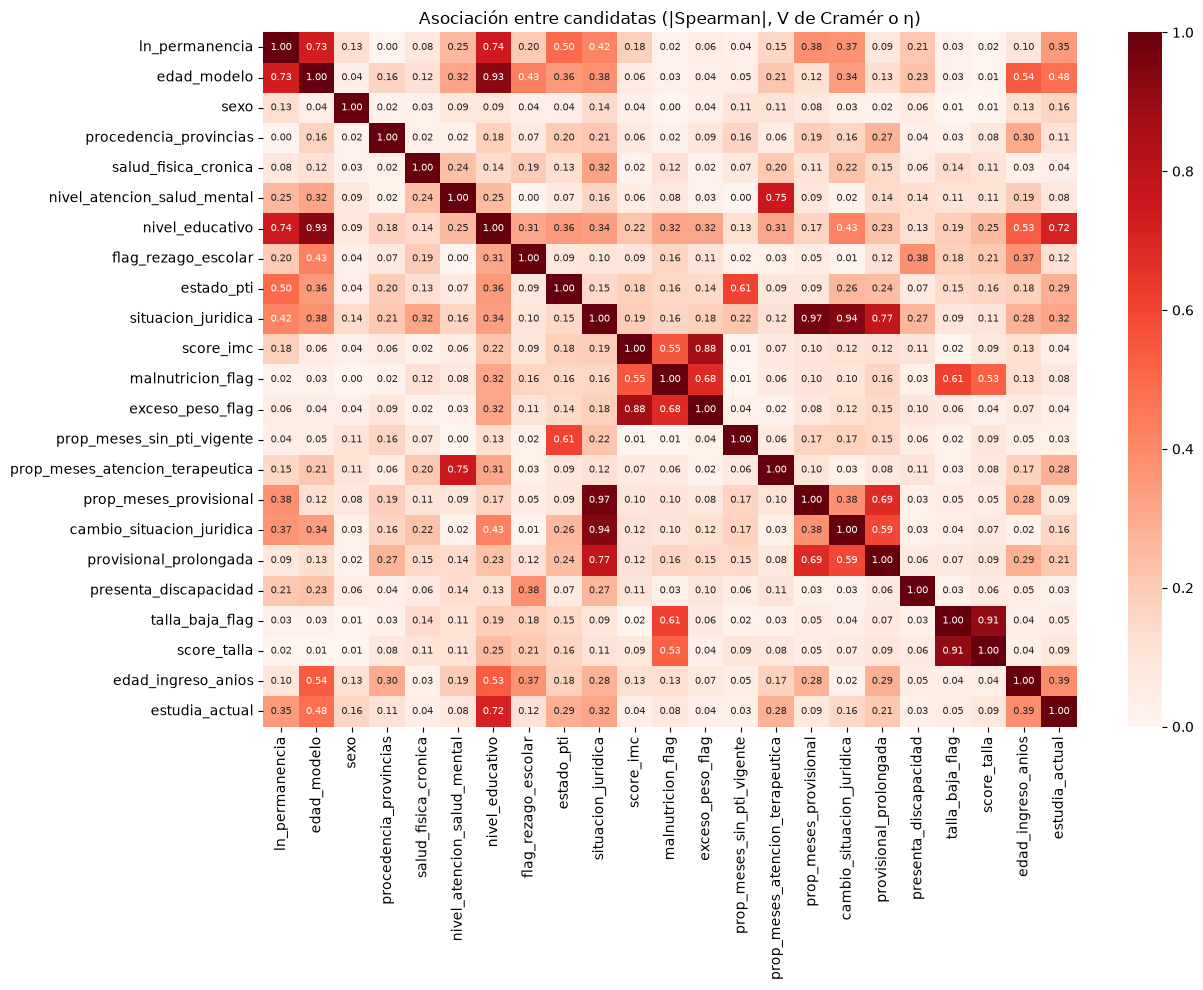

,variable_1,variable_2,asociación
5,situacion_juridica,prop_meses_provisional,0.970
6,situacion_juridica,cambio_situacion_juridica,0.941
2,edad_modelo,nivel_educativo,0.928
9,talla_baja_flag,score_talla,0.914
8,score_imc,exceso_peso_flag,0.878
7,situacion_juridica,provisional_prolongada,0.775
3,nivel_atencion_salud_mental,prop_meses_atencion_terapeutica,0.753
1,ln_permanencia,nivel_educativo,0.740
0,ln_permanencia,edad_modelo,0.734
4,nivel_educativo,estudia_actual,0.716


In [17]:
from scipy.stats import chi2_contingency, spearmanr


def cramer_v(a, b):
    t = pd.crosstab(a, b)
    if t.shape[0] < 2 or t.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


def eta2(cat, num):
    d = pd.DataFrame({'c': cat, 'n': num}).dropna()
    m = d['n'].mean()
    return (d.groupby('c')['n'].apply(lambda s: len(s) * (s.mean() - m) ** 2).sum()) / ((d['n'] - m) ** 2).sum()


vars_r = [c for c in CANDIDATAS if c != 'delta_imc']
asoc = pd.DataFrame(index=vars_r, columns=vars_r, dtype=float)
for i, a_ in enumerate(vars_r):
    for b_ in vars_r[i + 1:]:
        ta, tb = CANDIDATAS[a_][0], CANDIDATAS[b_][0]
        ca, cb = ta in ('cat', 'bin'), tb in ('cat', 'bin')
        if not ca and not cb:
            v = abs(spearmanr(X[a_], X[b_], nan_policy='omit')[0])
        elif ca and cb:
            v = cramer_v(X[a_], X[b_])
        else:
            v = np.sqrt(eta2(X[a_] if ca else X[b_], X[b_] if ca else X[a_]))   # raíz de η² (comparable con r)
        asoc.loc[a_, b_] = asoc.loc[b_, a_] = v
for c in vars_r:
    asoc.loc[c, c] = 1.0

plt.figure(figsize=(13, 10))
sns.heatmap(asoc.astype(float), vmin=0, vmax=1, cmap='Reds', annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Asociación entre candidatas (|Spearman|, V de Cramér o η)')
plt.tight_layout()
plt.show()

pares = [(a_, b_, round(asoc.loc[a_, b_], 3)) for i, a_ in enumerate(vars_r) for b_ in vars_r[i + 1:] if asoc.loc[a_, b_] >= 0.7]
pd.DataFrame(pares, columns=['variable_1', 'variable_2', 'asociación']).sort_values('asociación', ascending=False)

**Comentario 12 – resultado de los filtros.** Ninguna binaria candidata queda por debajo del 5 %, ni siquiera `presenta_discapacidad`, con 14 NNA (8.7 %), así que el filtro de prevalencia no excluye variables. Sí hay categorías chicas dentro de variables obligatorias (*Técnica* con 6 NNA, PTI *En trámite* con 3, situación jurídica *4* con 1). Se conservan porque son la codificación correcta según la institución, y en Gower una categoría solo afecta las distancias de quienes la tienen. Los filtros de redundancia y vacíos dejan esto:

| Variable candidata | Asociación | Decisión | Razón |
|---|---|---|---|
| `prop_meses_provisional`, `cambio_situacion_juridica` | 0.97 y 0.94 con `situacion_juridica` | **Excluidas** | El único cambio del periodo fue el paso de provisional a definitiva de 29 NNA en dic-2025, así que ambas repiten la situación actual |
| `nivel_educativo` | **0.93** con `edad_modelo` | **Descriptiva** | La edad explica el 86 % (η²) de la variación del nivel educativo: el nivel es la etapa escolar que corresponde a la edad. Lo que la educación agrega más allá de la edad, el **retraso**, ya entra en `flag_rezago_escolar`, que representa al área educativa del objetivo. Así se evita que la etapa de vida pese doble |
| `score_talla`, `talla_baja_flag` | 0.91 entre ellas | **Excluidas** | Las dos están contenidas en `malnutricion_flag`, que incluye la talla baja |
| `exceso_peso_flag` | 0.88 con `score_imc` | **Excluida** | Es `score_imc ≥ 2`, una copia del score |
| `provisional_prolongada` | 0.78 con `situacion_juridica` | **Descriptiva** | Es una combinación exacta de situación provisional y permanencia > 18 meses, que ya están en el modelo. Se usa para **evaluar** si los clusters reconocen el grupo prolongado del objetivo de negocio |
| `prop_meses_atencion_terapeutica` | 0.75 con el nivel de salud mental | **Excluida** | Repite el nivel actual, porque el soporte casi no cambia de intensidad |
| `estudia_actual` | 0.72 con el nivel educativo | **Excluida** | La define el nivel educativo ("No escolarizado") y la edad |
| `ln_permanencia` – `edad_modelo` | 0.73 | **Ambas se conservan** | Están asociadas (los mayores llevan más años), pero son conceptos distintos: la permanencia es central para el objetivo (situaciones prolongadas) y la edad se contrasta en las versiones |
| `edad_ingreso_anios` | – | **Excluida** | Es la edad menos la permanencia, una combinación de dos variables del modelo |
| `delta_imc` | – | **Descriptiva** | Vacía para 35 NNA (22 %), porque requiere 2 o más evaluaciones, y depende de la edad |

**Variables del modelo base (13):** `ln_permanencia`, `edad_modelo`, `sexo`, `procedencia_provincias`, `salud_fisica_cronica`, `presenta_discapacidad`, `nivel_atencion_salud_mental`, `flag_rezago_escolar`, `estado_pti`, `situacion_juridica`, `score_imc`, `malnutricion_flag` y `prop_meses_sin_pti_vigente`. Esta última resume el historial del PTI y aporta la persistencia que el estado del último mes no tiene. Cubren las cinco dimensiones del objetivo de negocio: **legal** (situación, permanencia), **administrativa** (estado e historial del PTI), **educativa** (rezago), **nutricional** (score y malnutrición) y **psicoemocional y salud** (nivel de atención, salud física, discapacidad), más los datos personales (edad, sexo, procedencia).

In [18]:
MODELO_BASE = ['ln_permanencia', 'edad_modelo', 'sexo', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad',
               'nivel_atencion_salud_mental', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'score_imc', 'malnutricion_flag',
               'prop_meses_sin_pti_vigente']
TIPOS = {c: CANDIDATAS[c][0] for c in MODELO_BASE}
print('Pares con asociación >= 0.7 dentro del modelo base:', [(a_, b_, v_) for a_, b_, v_ in pares if a_ in MODELO_BASE and b_ in MODELO_BASE])
print('Vacíos en el modelo base:', int(X[MODELO_BASE].isna().sum().sum()))
X[MODELO_BASE].describe(include='all').T[['count', 'unique', 'top', 'freq', 'mean', 'min', 'max']]

Pares con asociación >= 0.7 dentro del modelo base: [('ln_permanencia', 'edad_modelo', np.float64(0.734))]
Vacíos en el modelo base: 0


,count,unique,top,freq,mean,min,max
ln_permanencia,161.0,NaN,NaN,NaN,4.013104,0.7419,5.8078
edad_modelo,161.0,NaN,NaN,NaN,10.546087,0.09,18.0
sexo,161,2,M,89,NaN,NaN,NaN
procedencia_provincias,161.0,NaN,NaN,NaN,0.10559,0.0,1.0
salud_fisica_cronica,161.0,NaN,NaN,NaN,0.142857,0.0,1.0
presenta_discapacidad,161.0,NaN,NaN,NaN,0.086957,0.0,1.0
nivel_atencion_salud_mental,161.0,NaN,NaN,NaN,2.0,1.0,4.0
flag_rezago_escolar,161.0,NaN,NaN,NaN,0.111801,0.0,1.0
estado_pti,161,4,Vigente,93,NaN,NaN,NaN
situacion_juridica,161,4,3 Investigacion tutelar / Medida provisional,117,NaN,NaN,NaN


# 9. Consideraciones del documento de referencia y definición de versiones

| Consideración | Aplicación |
|---|---|
| **Hogar y motivo de ingreso:** el hogar no se modela, solo describe los clusters. Ninguna variable se usa como segmentación | `hogar` y `forma_ingreso` quedan en el dataset como descriptivas. No se arman modelos por separado por hogar ni por forma de ingreso (que además es "presunta desprotección" en el 97 %) |
| **Contrastar edad y sexo** (incluirlas o excluirlas) | **Versión 1** con edad y sexo, y dentro de ella un contraste **individual** (sin edad, sin sexo). **Versión 2** sin ninguna de las dos |
| **Distancia de Gower** | Es la métrica principal en v1 y v2. Numéricas y ordinales normalizadas por su rango; categóricas y binarias por coincidencia |
| **PCA o MDS solo si se justifica**, para un subgrupo; útil para visualizar | Se evalúa en la sección 10: PCA para el subgrupo numérico y **MCA** (análisis de correspondencias múltiples, el equivalente del PCA para variables cualitativas) para el subgrupo cualitativo. MDS sobre Gower para la proyección 2D |

Las tres versiones de dataset que se prueban en el clustering:

| Versión | Variables | Distancia / representación | Idea |
|---|---|---|---|
| **v1** | Modelo base (13) | Gower | Perfil completo, con la etapa de vida (edad) y el sexo |
| **v2** | Modelo base sin `edad_modelo` ni `sexo` (11) | Gower | Perfil **situacional** (legal, PTI, rezago, nutrición, salud y psicoemocional) sin que la edad domine la agrupación. La edad se usa después para describir los clusters |
| **v3** | Las mismas 13 variables de v1: las cualitativas reducidas por **MCA** y las numéricas estandarizadas | Euclidiana sobre las coordenadas | La misma información que v1 con otra representación, para ver si la reducción de dimensiones (sección 10) da grupos más separados o más estables |

In [19]:
VERSIONES = {
    'v1': MODELO_BASE,
    'v2': [c for c in MODELO_BASE if c not in ('edad_modelo', 'sexo')],
    'v3': MODELO_BASE,
}
for k, v in VERSIONES.items():
    print(k, len(v), v)

v1 13 ['ln_permanencia', 'edad_modelo', 'sexo', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'nivel_atencion_salud_mental', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'score_imc', 'malnutricion_flag', 'prop_meses_sin_pti_vigente']
v2 11 ['ln_permanencia', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'nivel_atencion_salud_mental', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'score_imc', 'malnutricion_flag', 'prop_meses_sin_pti_vigente']
v3 13 ['ln_permanencia', 'edad_modelo', 'sexo', 'procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'nivel_atencion_salud_mental', 'flag_rezago_escolar', 'estado_pti', 'situacion_juridica', 'score_imc', 'malnutricion_flag', 'prop_meses_sin_pti_vigente']


# 10. ¿Se justifica reducir dimensiones? PCA (numéricas), MCA (cualitativas) y MDS (Gower)

## 10.1 PCA sobre el subgrupo numérico y ordinal

In [20]:
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.decomposition import PCA

NUMERICAS = [c for c in VERSIONES['v3'] if TIPOS[c] in ('num', 'ord')]
Zn = (X[NUMERICAS] - X[NUMERICAS].mean()) / X[NUMERICAS].std(ddof=0)
chi2_b, p_b = calculate_bartlett_sphericity(Zn)
kmo_v, kmo_t = calculate_kmo(Zn)
pca_n = PCA().fit(Zn)
print('Variables:', NUMERICAS)
print(f'Bartlett: chi2 = {chi2_b:.1f}, p = {p_b:.3g} | KMO global = {kmo_t:.3f}')
print(pd.Series(kmo_v, index=NUMERICAS).round(3).to_string())
print('Varianza explicada (%):', (pca_n.explained_variance_ratio_ * 100).round(1))
print('Correlaciones (Spearman):')
X[NUMERICAS].corr(method='spearman').round(2)

Variables: ['ln_permanencia', 'edad_modelo', 'nivel_atencion_salud_mental', 'score_imc', 'prop_meses_sin_pti_vigente']
Bartlett: chi2 = 135.8, p = 3.07e-24 | KMO global = 0.510
ln_permanencia                 0.508
edad_modelo                    0.506
nivel_atencion_salud_mental    0.628
score_imc                      0.483
prop_meses_sin_pti_vigente     0.255
Varianza explicada (%): [36.7 20.5 19.8 17.9  5.1]
Correlaciones (Spearman):


,ln_permanencia,edad_modelo,nivel_atencion_salud_mental,score_imc,prop_meses_sin_pti_vigente
ln_permanencia,1.00,0.73,-0.25,-0.18,0.04
edad_modelo,0.73,1.00,-0.32,-0.06,0.05
nivel_atencion_salud_mental,-0.25,-0.32,1.00,0.06,-0.00
score_imc,-0.18,-0.06,0.06,1.00,0.01
prop_meses_sin_pti_vigente,0.04,0.05,-0.00,0.01,1.00


**Comentario 13 – PCA.** El subgrupo numérico y ordinal tiene solo 5 variables, y la única correlación relevante es **edad–permanencia (0.73)**; las demás están entre 0.00 y 0.32. Bartlett sale significativo (con 161 casos casi siempre lo es), pero el **KMO global es 0.51, por debajo del 0.6 aceptable**, y `prop_meses_sin_pti_vigente` tiene un KMO individual de 0.26. La PC1 (37 %) es justamente el par edad–permanencia, y las siguientes explican entre 18 % y 20 % cada una, es decir, más o menos una variable original cada una. **No se justifica PCA:** no comprime información (harían falta 4 de 5 componentes para el 95 %) y se perdería la lectura directa de cada variable.

## 10.2 MCA (análisis de correspondencias múltiples) sobre el subgrupo cualitativo

El MCA es un análisis de correspondencias sobre la tabla disyuntiva completa (una columna 0/1 por categoría). Como las inercias del MCA subestiman la estructura, se aplica la **corrección de Benzécri**, que considera solo los ejes con autovalor mayor que 1/Q (Q = número de variables).

In [21]:
CUALI = [c for c in VERSIONES['v3'] if TIPOS[c] in ('cat', 'bin')]


def mca(df, cols):
    Z = pd.get_dummies(df[cols].astype(str), prefix_sep='=').astype(float)
    P = Z / Z.values.sum()
    rmass, cmass = P.sum(1).values, P.sum(0).values
    S = (P.values - np.outer(rmass, cmass)) / np.sqrt(np.outer(rmass, cmass))
    U, s, Vt = np.linalg.svd(S, full_matrices=False)
    eig = s ** 2
    coords = (U * s) / np.sqrt(rmass)[:, None]              # coordenadas principales de las NNA
    return Z, eig, coords, Vt, cmass


Zd, eig, coords_mca, Vt_mca, cmass = mca(X, CUALI)
Q = len(CUALI)
benz = np.where(eig > 1 / Q, ((Q / (Q - 1)) * (eig - 1 / Q)) ** 2, 0)
tabla_mca = pd.DataFrame({'autovalor': eig[:10], 'inercia (%)': eig[:10] / eig.sum() * 100,
                          'Benzécri (%)': benz[:10] / benz.sum() * 100}).round(2)
tabla_mca['Benzécri acumulada (%)'] = tabla_mca['Benzécri (%)'].cumsum().round(1)
print(f'Variables cualitativas: {Q} -> {Zd.shape[1]} categorías | ejes con autovalor > 1/Q: {(eig > 1 / Q).sum()}')
tabla_mca.index = [f'Dim{i + 1}' for i in range(len(tabla_mca))]
tabla_mca

Variables cualitativas: 8 -> 20 categorías | ejes con autovalor > 1/Q: 6


,autovalor,inercia (%),Benzécri (%),Benzécri acumulada (%)
Dim1,0.21,14.16,64.89,64.9
Dim2,0.18,11.92,24.54,89.4
Dim3,0.16,10.35,7.75,97.2
Dim4,0.14,9.48,2.51,99.7
Dim5,0.13,8.73,0.30,100.0
Dim6,0.13,8.42,0.01,100.0
Dim7,0.12,7.81,0.00,100.0
Dim8,0.11,7.41,0.00,100.0
Dim9,0.11,7.13,0.00,100.0
Dim10,0.09,6.15,0.00,100.0


In [22]:
# Contribución de cada categoría a las dos primeras dimensiones
contrib = pd.DataFrame((Vt_mca[:3].T ** 2) * 100, index=Zd.columns, columns=['Dim1', 'Dim2', 'Dim3'])
for dim in ['Dim1', 'Dim2']:
    print(f'\n{dim} – categorías con mayor contribución (%):')
    print(contrib[dim].sort_values(ascending=False).head(6).round(1).to_string())


Dim1 – categorías con mayor contribución (%):
flag_rezago_escolar=1                                  19.9
presenta_discapacidad=1                                19.8
salud_fisica_cronica=1                                 18.3
situacion_juridica=4 Sin definir / En observacion      12.4
estado_pti=Sin PTI                                      4.6
situacion_juridica=1 Tutela / Medida judicial firme     3.7

Dim2 – categorías con mayor contribución (%):
procedencia_provincias=1                                           24.5
situacion_juridica=1 Tutela / Medida judicial firme                21.4
estado_pti=Vencido                                                 14.0
situacion_juridica=3 Investigacion tutelar / Medida provisional     8.4
flag_rezago_escolar=1                                               7.6
presenta_discapacidad=1                                             4.5


**Comentario 14 – MCA.** Las 8 variables cualitativas del modelo generan 20 categorías. La inercia bruta de cada eje es baja (14 % y 12 %), algo normal en un MCA porque la codificación disyuntiva infla la dimensión. Con la **corrección de Benzécri**, la estructura útil se concentra en pocos ejes: **Dim1 = 64.9 %, Dim2 = 24.5 % (acumulado 89.4 %) y Dim3 = 7.8 % (97.2 %)**. Las dos primeras tienen una lectura clara:
- **Dim1 – necesidades especiales:** la definen el rezago escolar, la discapacidad y la salud física crónica (con aportes de 18 % a 20 % cada una), además del caso judicial sin definir. Separa a las NNA con necesidades de salud o educativas del resto.
- **Dim2 – trayectoria legal y procedencia:** la definen haber nacido en provincias, la medida firme (tutela/definitiva) y el PTI vencido, frente a la medida provisional.

**El MCA sí se justifica para el subgrupo cualitativo**, como sugiere el documento de referencia: con 3 ejes se resume más del 90 % de la inercia corregida de 8 variables, y los ejes se pueden interpretar. Se usa en la **versión 3**, con esas **3 dimensiones** (97 % de la inercia corregida).

## 10.3 MDS sobre la distancia de Gower (para visualizar)

Stress-1 de Kruskal por número de dimensiones: {1: np.float64(0.506), 2: np.float64(0.282), 3: np.float64(0.193), 4: np.float64(0.137), 5: np.float64(0.108)}


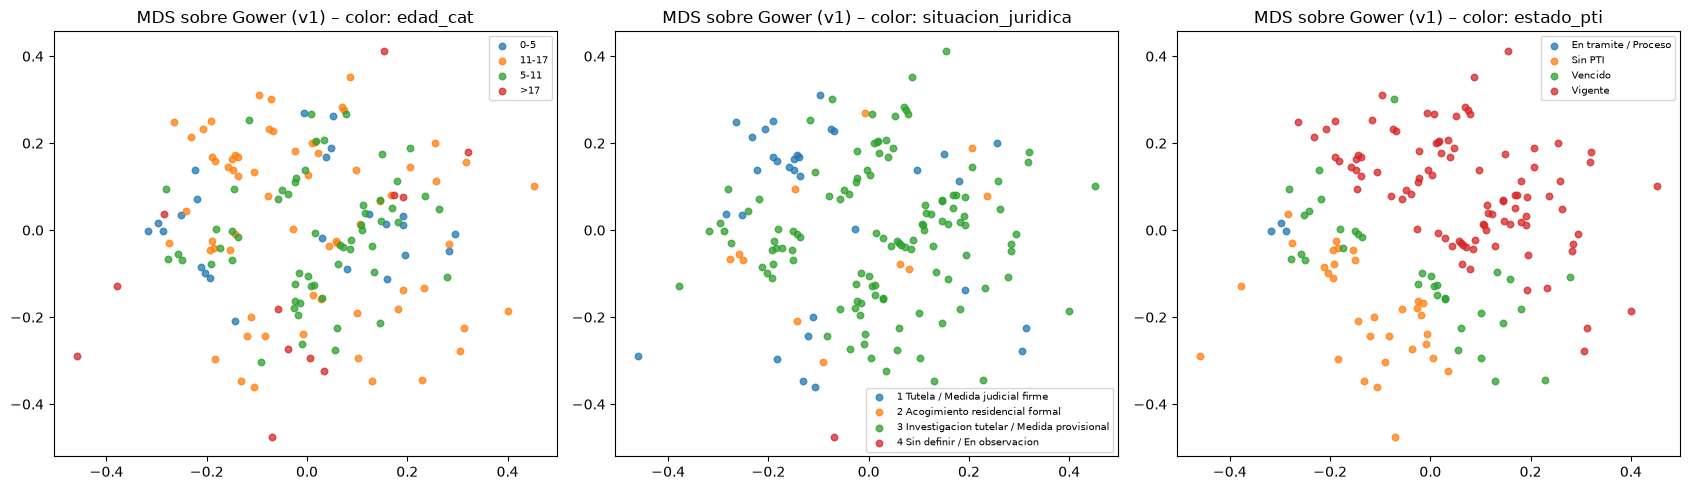

In [23]:
def gower(df, tipos):
    """Distancia de Gower: numéricas/ordinales |x-y|/rango; categóricas/binarias 0 si coinciden y 1 si no.
    Los vacíos se excluyen par a par (promedio sobre las variables disponibles)."""
    n = len(df)
    num, den = np.zeros((n, n)), np.zeros((n, n))
    for c, t in tipos.items():
        x = df[c]
        ok = np.asarray(x.notna())
        valid = ok[:, None] & ok[None, :]
        if t in ('num', 'ord'):
            v = np.asarray(x, dtype=float)
            rango = np.nanmax(v) - np.nanmin(v)
            dist = np.abs(v[:, None] - v[None, :]) / rango if rango > 0 else np.zeros((n, n))
        else:
            v = np.asarray(x.astype(str), dtype=object)
            dist = (v[:, None] != v[None, :]).astype(float)
        num += np.where(valid, dist, 0)
        den += valid
    return num / den


from sklearn.manifold import MDS
D1 = gower(X, {c: TIPOS[c] for c in VERSIONES['v1']})
from scipy.spatial.distance import pdist, squareform


def stress1(D, emb):
    """Stress-1 de Kruskal: sqrt(sum (d_ij - dist_ij)^2 / sum d_ij^2). < 0.1 bueno, 0.1-0.2 aceptable, > 0.2 pobre."""
    E = squareform(pdist(emb))
    iu = np.triu_indices_from(D, 1)
    return np.sqrt(((D[iu] - E[iu]) ** 2).sum() / (D[iu] ** 2).sum())


stress, embs = {}, {}
for k in (1, 2, 3, 4, 5):
    embs[k] = MDS(n_components=k, dissimilarity='precomputed', random_state=42, n_init=4).fit_transform(D1)
    stress[k] = stress1(D1, embs[k])
print('Stress-1 de Kruskal por número de dimensiones:', {k: round(v, 3) for k, v in stress.items()})
mds2 = embs[2]
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a_, var in zip(ax, ['edad_cat', 'situacion_juridica', 'estado_pti']):
    for cat_ in sorted(X[var].unique()):
        m = (X[var] == cat_).values
        a_.scatter(mds2[m, 0], mds2[m, 1], s=22, alpha=.75, label=cat_)
    a_.set_title(f'MDS sobre Gower (v1) – color: {var}')
    a_.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Comentario 15 – MDS.** El **stress-1 de Kruskal en 2D es 0.28**, un ajuste pobre (> 0.2). Recién con 4 dimensiones baja a 0.14, aceptable. La distancia de Gower entre NNA no cabe en un plano sin distorsión, así que **el MDS solo se usa para visualizar** los clusters en 2D, sin modelar sobre él, como sugiere el documento. En el gráfico, la estructura más visible es la del **PTI**: los vigentes se ubican a un lado y los vencidos o sin PTI al otro. La situación jurídica firme se concentra en una zona, mientras que la edad aparece mezclada. No se ven grupos separados con nitidez, lo que anticipa siluetas moderadas, una estructura más continua que en bloques.

**Conclusión de la sección 10:**
- **PCA:** no se justifica (KMO 0.51, sin compresión real).
- **MCA:** se justifica para el bloque cualitativo (3 ejes, 97 % de la inercia corregida) y se usa en la v3.
- **MDS:** solo para visualizar. La métrica principal sigue siendo **Gower** sobre las variables originales (v1 y v2), porque conserva la lectura directa de cada variable, que es lo que necesita el equipo técnico.

# 11. Listas para pedir datos a la institución

Varias respuestas (INC-18, INC-19 e INC-20) dicen *"Enviar lista de IDs para recuperar este dato"*. Se generan esas listas, para que al recibir los datos baste volver a ejecutar el cuaderno.

In [24]:
sol_disc = X[(X['presenta_discapacidad'] == 1)][['id_original', 'tipo_discapacidad', 'grado_discapacidad', 'ultimo_periodo']]
sol_ini = fichas[(fichas['nivel_edu'] == 'Inicial') & fichas['grado_n'].isna()].groupby('id_original')['periodo'].agg(['min', 'max', 'size'])
sol_geo = X[X['distrito_vacio'] == 1][['id_original', 'departamento_nac', 'provincia_nac', 'ultimo_periodo']]
sol_cron = r.groupby(['id_persona', 'id_recuperado'])[['fecha_nacimiento', 'nom_Fecha de ingreso']].first().reset_index()
print(f'INC-18 discapacidad (grado de severidad): {len(sol_disc)} NNA')
print(f'INC-19 "Inicial" sin edad: {len(sol_ini)} códigos')
print(f'INC-20 sin distrito de nacimiento: {len(sol_geo)} NNA')
print(f'INC-01/06 códigos recuperados que la institución debe confirmar: {len(sol_cron)} NNA')

INC-18 discapacidad (grado de severidad): 14 NNA
INC-19 "Inicial" sin edad: 34 códigos
INC-20 sin distrito de nacimiento: 16 NNA
INC-01/06 códigos recuperados que la institución debe confirmar: 16 NNA


# 12. Guardado del dataset final, el diccionario y las versiones

In [25]:
USO = {c: 'modelo (v1, v2, v3)' for c in VERSIONES['v2']}
USO.update({'edad_modelo': 'modelo (v1, v3)', 'sexo': 'modelo (v1)'})
DESCRIPCION = {
    'id_original': 'Código de la ficha nominal', 'id_recuperado': 'Tratamiento INC-01/06 aplicado (No = sin tratamiento)',
    'ultimo_periodo': 'Último mes con ficha nominal (Enfoque B)', 'activo_al_corte': '1 = presente en 2026-07; 0 = egreso presunto (INC-16)',
    'n_meses_ficha': 'Meses con ficha en la ventana', 'sexo': 'Sexo', 'meses_permanencia': 'Meses desde el ingreso al último mes',
    'ln_permanencia': 'ln(1 + meses de permanencia)', 'permanencia_cat': '<1, 1-3, 3-5, >5 años', 'edad_anios': 'Edad al último mes',
    'edad_modelo': 'Edad acotada en 18 (para el modelo)', 'edad_cat': '0-5, 5-11, 11-17, >17', 'edad_ingreso_anios': 'Edad al ingreso',
    'departamento_nac': 'Departamento de nacimiento (INC-20 corregido)', 'provincia_nac': 'Provincia de nacimiento',
    'procedencia_provincias': '1 = nació fuera de Lima Metropolitana y Callao', 'region_natural': 'Costa/Sierra/Selva (lugar de nacimiento)',
    'distrito_vacio': '1 = sin distrito (solicitar, INC-20)', 'salud_fisica_cronica': '1 = alguna patología o tratamiento continuo en el historial',
    'meses_condicion_salud': 'Meses con condición de salud distinta de saludable', 'presenta_discapacidad': '1 = presenta discapacidad (INC-18)',
    'tipo_discapacidad': 'Tipo general de discapacidad', 'grado_discapacidad': 'Grado registrado (por completar, INC-18)',
    'nivel_atencion_salud_mental': '1 sin atención, 2 acompañamiento, 3 terapia/psicoterapia, 4 especializada externa (INC-10)',
    'prop_meses_atencion_terapeutica': 'Proporción de meses con nivel >= 3', 'nivel_educativo': 'No escolarizado, Inicial, Primaria, Secundaria, Técnica',
    'grado_texto': 'Grado tal como se registró', 'inicial_sin_edad': '1 = "Inicial" sin edad, asignada por la edad normativa (INC-19)',
    'anios_escolaridad': 'Años teóricos de escolaridad (1.º primaria = 0)', 'desfase_escolar': 'edad al 31-mar - (años de escolaridad + 6)',
    'flag_rezago_escolar': '1 = desfase > 1 año', 'estudia_actual': '1 = estudia en el último mes',
    'estado_pti': 'Vigente, En trámite / Proceso, Vencido, Sin PTI (INC-08)', 'plazo_vigencia_pti': '3, 6, 12, 18+, Permanencia, Sin PTI',
    'vigencia_anio_corregido': '1 = vigencia anterior a la elaboración, año corregido (INC-08 b)',
    'prop_meses_sin_pti_vigente': 'Proporción de meses observados sin PTI vigente', 'situacion_juridica': '4 categorías de negocio (INC-11)',
    'instancia': 'UPE/UIT, Juzgado o DGA', 'cambio_situacion_juridica': '1 = cambió de categoría en el periodo',
    'prop_meses_provisional': 'Proporción de meses en medida provisional', 'provisional_prolongada': '1 = medida provisional y más de 18 meses',
    'forma_ingreso': 'Motivo / forma de ingreso (descriptiva)', 'n_eval_nutricion': 'Evaluaciones nutricionales (2026)',
    'peso_ficha': 'Nivel de peso según la ficha (0-3)', 'talla_ficha': 'Nivel de talla según la ficha (-3-0)',
    'fuente_nutricion': 'Evaluación nutricional o ficha nominal', 'hogar': 'Hogar (solo descriptiva)', 'casa': 'Casa',
    'periodo_ultima_eval': 'Mes de la última evaluación', 'imc_ultimo': 'IMC de la última evaluación', 'score_imc': 'Score ordinal -3..+3 del estado de peso',
    'score_talla': 'Score -3..+1 de talla para la edad', 'delta_imc': 'IMC último - IMC primero (>= 2 evaluaciones)',
    'prop_eval_exceso': 'Proporción de evaluaciones con sobrepeso/obesidad', 'prop_eval_talla_baja': 'Proporción de evaluaciones con talla baja',
    'nutricion_imputada': '1 = sin evaluación ni ficha: score imputado con 0', 'exceso_peso_flag': '1 = sobrepeso u obesidad',
    'talla_baja_flag': '1 = talla baja o talla baja severa', 'malnutricion_flag': '1 = bajo peso, talla baja o exceso',
    'score_imc_cat': 'Score de IMC en texto',
}
dicc = describir(X)
dicc['descripcion'] = [DESCRIPCION.get(c, '') for c in dicc.index]
dicc['uso'] = [USO.get(c, 'descriptiva / trazabilidad') for c in dicc.index]
dicc['tipo_gower'] = [TIPOS.get(c, '') for c in dicc.index]
versiones_df = pd.DataFrame([{'version': k, 'variable': c, 'tipo_gower': TIPOS[c]} for k, v in VERSIONES.items() for c in v])

RUTA_DATASET = RUTA_SALIDA / 'Dataset_final_enfoqueB.xlsx'
with pd.ExcelWriter(RUTA_DATASET) as w:
    X.reset_index().to_excel(w, sheet_name='dataset', index=False)
    dicc.reset_index().to_excel(w, sheet_name='diccionario', index=False)
    versiones_df.to_excel(w, sheet_name='versiones', index=False)
with pd.ExcelWriter(RUTA_EVID / 'solicitudes_a_la_institucion.xlsx') as w:
    sol_disc.to_excel(w, sheet_name='INC18_grado_discapacidad')
    sol_ini.to_excel(w, sheet_name='INC19_inicial_sin_edad')
    sol_geo.to_excel(w, sheet_name='INC20_sin_distrito')
    sol_cron.to_excel(w, sheet_name='INC01_06_por_confirmar', index=False)
with pd.ExcelWriter(RUTA_EVID / 'evidencias_tratamientos.xlsx') as w:
    claves_inc01.to_excel(w, sheet_name='INC01_claves', index=False)
    cruce.to_excel(w, sheet_name='INC01_06_cruce_nutricion', index=False)
    excl_antes.to_excel(w, sheet_name='INC06_fichas_antes_ingreso', index=False)
    eq_legal.to_excel(w, sheet_name='INC11_equivalencias', index=False)
    muestra_sm.to_excel(w, sheet_name='INC10_salud_mental', index=False)
    control.to_excel(w, sheet_name='control_limpieza', index=False)
    tabla_mca.to_excel(w, sheet_name='MCA_inercia')
fichas.drop(columns=['fin_mes']).to_excel(RUTA_SALIDA / 'panel_mensual_enfoqueB.xlsx', index=False)   # panel mensual con las codificaciones (trazabilidad)
print('Guardado:', RUTA_DATASET.relative_to(BASE))
print('Dimensiones:', X.shape, '| variables de modelo (v1):', len(VERSIONES['v1']))

Guardado: Resultados_EnfoqueB\Dataset_final_enfoqueB.xlsx
Dimensiones: (161, 60) | variables de modelo (v1): 13


**Comentario 16:** se guarda `Resultados_EnfoqueB/Dataset_final_enfoqueB.xlsx` con tres hojas:
- `dataset`: 161 NNA, con las variables de modelo, las descriptivas y la trazabilidad.
- `diccionario`: descripción, tipo, vacíos, uso (modelo o descriptiva) y tipo para Gower de cada variable.
- `versiones`: variables de las versiones v1, v2 y v3.

El panel mensual codificado queda en `panel_mensual_enfoqueB.xlsx`. En `Evidencias_Paso4B/` quedan las evidencias de cada tratamiento y las **listas para la institución** (grado de discapacidad, "Inicial" sin edad, distrito faltante y los 16 NNA recuperados por confirmar). Los notebooks `Paso 5 - Clustering v1/v2/v3` leen este archivo.